# Choosing an equity + government-bond portfolio on Trade Republic

**Investor.** Italian tax resident. €1,000 up front, then €100 a month through Trade Republic
savings plans (free; €1 on the one-off order). Horizon about 10 years. The portfolio is one
equity sleeve plus one government-bond sleeve; **which** equity and **which** bond are both open.

**The six steps, in order.** Each step narrows what the next one has to consider.

| § | Step | Output |
|---|---|---|
| 1 | Buyable universe | Every index with a UCITS ETF on Trade Republic, its best fund, and that fund's measured cost |
| 2 | Equity screen | Return, risk, crises and downside for every buyable index — and how much of it is noise |
| 3 | Equity shortlist | Five sleeves chosen on properties that persist, spanning the real choices |
| 4 | Bond sleeves | Each bond candidate judged *as a partner* to each shortlisted equity sleeve |
| 5 | Weights | Sharpe, crisis replay, stress tests and a simulation of the actual plan after Italian tax |
| 6 | Real ETFs and the decision | Every cost layer, then the options side by side |

**No index is the default.** Tests are pairwise and symmetric; nothing is measured "against
MSCI World" as if World were the incumbent.

All series are monthly, in **EUR**, total return. Not financial advice.

## What the evidence says before we start

| Topic | Evidence | Consequence here |
|---|---|---|
| Comparing Sharpe ratios | Ledoit & Wolf (2008) HAC test; a new "winner" needs t > 3 (Harvey, Liu & Zhu 2016) | Pairwise tests with a correction for the number of pairs |
| Factor indexes | Returns fall ~58% after publication (McLean & Pontiff 2016); smart-beta indexes earn ~+3%/yr *before* their ETF launches and ≈0 after (Huang, Song & Xiang 2024) | Judge factor sleeves on what **persisted after launch** |
| Optimisers vs fixed weights | No optimiser reliably beats 1/N out of sample; errors in expected returns are ~10× more harmful than in variances (DeMiguel et al. 2009; Chopra & Ziemba 1993) | Weights chosen from simulated outcomes, not from historical means |
| Stock–bond correlation | Negative 2000–2021, positive when inflation dominates (1970s–90s, 2022–) (Brixton et al. 2023) | Every bond result is shown in both regimes |
| Currency | Hedge foreign bonds; unhedged equity is fine for a EUR investor (Campbell, Serfaty-de Medeiros & Viceira 2010) | Bonds: EUR or EUR-hedged only |
| Bond returns | Over a holding period near a bond fund's duration, the starting yield is the best single predictor of its return | Bond sleeves are compared on **today's yields**, not on 2004–2026 history |
| Simulation | Stationary block bootstrap (Politis & Romano 1994); re-centred on capital-market assumptions | History supplies the shapes; assumptions supply the means |

In [1]:
import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
from IPython.display import display

import design as D
import etfs as ETF
import pfutils as pf

pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 30)
END = pd.Timestamp("2026-09-30")  # last complete month in this run

INK, INK2, MUTED, GRID, BASE, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
SLOT = ["#2a78d6", "#1baf7a", "#eda100", "#008300", "#4a3aa7", "#e34948", "#e87ba4", "#eb6834"]
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": ["Helvetica Neue", "Arial", "DejaVu Sans"], "font.size": 10,
    "text.color": INK, "axes.labelcolor": INK2, "axes.edgecolor": BASE, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2,
    "ytick.labelcolor": INK2, "lines.linewidth": 2, "legend.frameon": False, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "figure.dpi": 110,
})
pct0 = mtick.PercentFormatter(1.0, decimals=0)
pct1 = mtick.PercentFormatter(1.0, decimals=1)
eur_k = mtick.FuncFormatter(lambda v, _: f"€{v/1000:.1f}k")
P1 = lambda cols: {c: "{:.1%}" for c in cols}
EUR0 = lambda cols: {c: "€{:,.0f}" for c in cols}

eur1m = pf.ecb_series("FM/M.U2.EUR.RT.MM.EURIBOR1MD_.HSTA") / 100
eur1m.index = eur1m.index + pd.offsets.MonthEnd(0)
RF = eur1m / 12  # monthly EUR risk-free (1-month Euribor)

eq = pd.concat([D.equity_indexes(), D.other_indexes(END)], axis=1).loc[:END]
bonds, blong = D.bond_indexes(END)
bonds = pd.concat([bonds, D.ust_hedged_buckets(END)], axis=1)
bonds = bonds.rename(columns={"US Treasury (EUR hedged)": "UST All (EUR hedged)"})
L = D.long_equity_eur(END)
print(f"{eq.shape[1]} equity indexes, {bonds.shape[1]} bond series, long equity history from {L.index[0]:%Y-%m}")

28 equity indexes, 10 bond series, long equity history from 1975-02


## 1 · The buyable universe

An index is in the screen only if a **UCITS ETF tracking it can be bought on a Trade Republic
savings plan**. Trade Republic itself excludes little — most UCITS ETFs are on its plan list —
so the binding constraint is whether a European fund exists at all.

**Which index does each fund actually track?** Not always the one in its name. Each fund's
monthly returns were matched against every candidate index; the one it tracks is the one it
follows with the smallest real deviation.

**What does each fund actually cost?** Not its TER. The measured cost is the trend in the
cumulative gap between fund and index — it nets the fee against securities lending and against
**withholding tax**: MSCI's *net* indexes assume US dividends are taxed at 30%, while an Irish
fund pays 15% under the US–Ireland treaty, which is worth ~0.15–0.25%/yr on a world fund.

Why a trend and not the simple end-to-end gap? Xetra closes at 17:30 CET; MSCI World closes
after New York. A monthly fund–index gap mostly reverses the next month (autocorrelation ≈ −0.4),
so the end-to-end figure depends on two noisy prices. The trend uses every month; on 200
simulated funds with a known 0.15% cost it was 4× more precise.

In [2]:
def measure(recs, series, trust=True):
    rows = []
    for f in recs:
        k = f["index"]
        try:
            r = D.etf_returns(f["ticker"], END, f["start"])
        except Exception:
            r = None
        est = D.drag_slope(r, series[k]) if r is not None else None
        rows.append({"Index": k, "ETF": f["name"], "Ticker": f["ticker"], "ISIN": f["isin"], "TER": f["ter"],
                     "Measured cost /yr": est["Drag"] if est else np.nan,
                     "± (1 s.e.)": est["SE"] if est else np.nan,
                     "Real deviation": est["Real deviation"] if est else np.nan,
                     "Since": est["From"] if est else None, "Months": est["Months"] if est else 0,
                     "AUM €bn": f["aum_bn"], "Dom.": f["dom"], "Acc.": "Acc" if f["acc"] else "Dist",
                     "Repl.": f["repl"], "TR plan": f["tr_plan"]})
    return pd.DataFrame(rows)

etf_eq = measure(ETF.records(ETF.EQUITY), eq)
display(etf_eq.style.format({"TER": "{:.2%}", "Measured cost /yr": "{:+.2%}", "± (1 s.e.)": "{:.2%}",
                             "Real deviation": "{:.2%}", "AUM €bn": "{:.1f}"}, na_rep="—").hide(axis="index"))
print("Measured cost below the TER (or negative) is normal for Irish funds holding US shares — see the text above.")
print("TR plan: Y = listed by both Italian broker tables, Y* = justETF Italy only. Trade Republic publishes no list; check in the app.")
print("FTSE funds are shown against the nearest MSCI index, so their 'cost' includes the difference between the two indexes.")

Index,ETF,Ticker,ISIN,TER,Measured cost /yr,± (1 s.e.),Real deviation,Since,Months,AUM €bn,Dom.,Acc.,Repl.,TR plan
World,UBS Core MSCI World,UETW.DE,IE00BD4TXV59,0.06%,+0.01%,0.06%,0.61%,2020-06,76,11.6,IE,Acc,Physical,Y
World,Xtrackers MSCI World 1C,XDWD.DE,IE00BJ0KDQ92,0.12%,-0.04%,0.02%,0.51%,2014-12,142,22.1,IE,Acc,Physical,Y
World,iShares Core MSCI World,EUNL.DE,IE00B4L5Y983,0.20%,-0.03%,0.02%,0.59%,2010-01,201,133.4,IE,Acc,Physical,Y
World,SPDR MSCI World,SPPW.DE,IE00BFY0GT14,0.12%,-0.11%,0.04%,0.59%,2019-06,88,18.7,IE,Acc,Physical,Y*
World,Amundi Core MSCI World,MWRE.DE,IE000BI8OT95,0.12%,-0.21%,0.40%,0.45%,2025-03,19,15.7,IE,Acc,Physical,Y*
World,Invesco MSCI World,SC0J.DE,IE00B60SX394,0.05%,+0.01%,0.03%,0.66%,2010-06,196,9.4,IE,Acc,Swap,Y
ACWI,SPDR MSCI ACWI,SPYY.DE,IE00B44Z5B48,0.12%,+0.04%,0.02%,0.57%,2011-09,181,18.1,IE,Acc,Physical,Y
ACWI,iShares MSCI ACWI,IUSQ.DE,IE00B6R52259,0.20%,+0.13%,0.02%,0.57%,2012-02,176,32.2,IE,Acc,Physical,Y
ACWI,Vanguard FTSE All-World (FTSE index),VWCE.DE,IE00BK5BQT80,0.14%,+0.06%,0.04%,0.54%,2019-11,83,55.1,IE,Acc,Physical,Y
ACWI,Invesco FTSE All-World (FTSE index),FWIA.DE,IE000716YHJ7,0.15%,+0.07%,0.13%,0.46%,2023-10,36,4.3,IE,Acc,Physical,Y


Measured cost below the TER (or negative) is normal for Irish funds holding US shares — see the text above.
TR plan: Y = listed by both Italian broker tables, Y* = justETF Italy only. Trade Republic publishes no list; check in the app.
FTSE funds are shown against the nearest MSCI index, so their 'cost' includes the difference between the two indexes.


**The cost each index carries into the screen** is that of its best fund. "Best" is judged on
measured cost **plus one standard error**, so a fund cannot win on a lucky, noisy estimate;
funds with under three years of history fall back on their TER. Among the candidates, physically
replicated funds confirmed on Trade Republic by both Italian broker tables come first; swap-based
and single-source funds are used only when nothing else exists. FTSE funds are never the best fund
for an MSCI index. Every later step uses returns **after** this cost.

Exposures in MSCI's catalogue that cannot be bought:

In [3]:
def best_cost(tab):
    ok = tab[(tab["Acc."] == "Acc") & ~tab["ETF"].str.contains("FTSE")].copy()
    long_ = ok["Months"] >= 36
    ok["Cost used"] = np.where(long_, ok["Measured cost /yr"], ok["TER"])
    ok["Rank on"] = np.where(long_, ok["Measured cost /yr"] + ok["± (1 s.e.)"], ok["TER"])
    ok["Tier"] = np.where(ok["Repl."] != "Physical", 2, np.where(ok["TR plan"] == "Y", 0, 1))
    ok = ok.dropna(subset=["Cost used"]).sort_values(["Tier", "Rank on"])
    return ok.groupby("Index").head(1).set_index("Index").sort_values("Cost used")

BEST_EQ = best_cost(etf_eq)
display(BEST_EQ[["ETF", "Ticker", "TER", "Cost used", "Months", "Repl.", "TR plan"]]
        .style.format({"TER": "{:.2%}", "Cost used": "{:+.2%}"}, na_rep="—"))
for k, why in ETF.NOT_INVESTABLE.items():
    print(f"  ✗ {k}: {why}")

INV = list(BEST_EQ.index)
EQN = pd.DataFrame({k: D.net_of_cost(eq[k], BEST_EQ.loc[k, "Cost used"]) for k in INV})
print(f"\n{len(INV)} buyable equity indexes go into the screen, each net of its best fund's cost.")

,ETF,Ticker,TER,Cost used,Months,Repl.,TR plan
Index,,,,,,,
EMU,iShares Core MSCI EMU,SXR7.DE,0.12%,-0.38%,195,Physical,Y
S&P 500,iShares Core S&P 500,SXR8.DE,0.07%,-0.19%,189,Physical,Y
USA,Xtrackers MSCI USA 1C,XD9U.DE,0.03%,-0.15%,145,Physical,Y
Europe,SPDR MSCI Europe,SPYE.DE,0.08%,-0.12%,138,Physical,Y
World Enhanced Value,Xtrackers MSCI World Value 1C,XDEV.DE,0.25%,-0.06%,118,Physical,Y
World,Xtrackers MSCI World 1C,XDWD.DE,0.12%,-0.04%,142,Physical,Y
EM IMI,iShares Core MSCI EM IMI,IS3N.DE,0.18%,+0.00%,144,Physical,Y
Europe Small Cap,Xtrackers MSCI Europe Small Cap 1C,XXSC.DE,0.30%,+0.03%,208,Physical,Y
World Small Cap,iShares MSCI World Small Cap,IUSN.DE,0.35%,+0.03%,98,Physical,Y


  ✗ ACWI Min Vol: No UCITS ETF. The US-listed ACWV cannot be bought by EU retail (PRIIPs/KID).
  ✗ World Quality: Every 'World Quality' ETF tracks the Sector Neutral variant (see World Quality SN).
  ✗ World Value: Every 'World Value' ETF tracks Enhanced Value or another variant (see World Enhanced Value).
  ✗ World Growth: No UCITS ETF.
  ✗ World Multi-Factor: No UCITS ETF since iShares moved IBCZ to a STOXX index on 2025-01-22.
  ✗ USA Small Cap: Only screened or optimised variants exist, not the plain index.
  ✗ World High Dividend: The only plain-index UCITS ETF (Fineco AM) is not on Trade Republic.

21 buyable equity indexes go into the screen, each net of its best fund's cost.


## 2 · Equity screen: every buyable index, after cost

Window **2001-01 → 2026-09**, the longest one every index covers. It includes the end of the
dot-com bust, the GFC, the euro crisis, COVID and 2022.

**The market** for beta and capture is MSCI ACWI IMI — every listed company in the world, large
and small, developed and emerging. It is not a default choice; it is what "the market" means in
the definition of beta.

Columns, all annualised:
- `Sharpe` — mean return above cash ÷ volatility. `Sortino` — the same, but only downside months count as risk.
- `Calmar` — CAGR ÷ |worst drawdown|: growth per unit of the single worst loss.
- `Ulcer` — root-mean-square drawdown: depth *and* time under water across the whole history.
  `Martin` — CAGR ÷ ulcer, the duration-aware version of Calmar.
- `Beta` — how much the index moves per 1% move in the market. `Down capture` — its average fall in
  months the market fell, as a share of the market's fall.

In [4]:
E = EQN.loc["2001-01":END].dropna(how="all")
MKT = E["ACWI IMI"]
rf = RF.reindex(E.index).ffill()

def screen_row(s, mkt, rf_):
    st = D.downside_stats(s, rf_)
    cap = D.capture_ratios(s, mkt)
    return {"CAGR": st["CAGR"], "Volatility": st["Volatility"], "Sharpe": st["Sharpe"], "Sortino": st["Sortino"],
            "Max drawdown": st["Max drawdown"], "Calmar": st["Calmar"], "Ulcer": D.ulcer_index(s),
            "Martin": D.martin_ratio(s), "Worst 12m": st["Worst 12m"], "CVaR 95% (1m)": st["CVaR 95% (1m)"],
            "Beta": D.beta(s, mkt), "Down capture": cap["Down capture"], "Up capture": cap["Up capture"]}

SCR = pd.DataFrame({c: screen_row(E[c], MKT, rf) for c in E}).T.sort_values("Volatility")
SCR.insert(0, "Fund cost", BEST_EQ["Cost used"])
fmt_scr = (P1(["CAGR", "Volatility", "Max drawdown", "Worst 12m", "CVaR 95% (1m)"]) | {"Fund cost": "{:+.2%}"}
           | {c: "{:.2f}" for c in ["Sharpe", "Sortino", "Calmar", "Ulcer", "Martin", "Beta", "Down capture", "Up capture"]})
display(SCR.style.format(fmt_scr)
        .background_gradient(cmap="RdYlGn", subset=["Sharpe", "Sortino", "Calmar", "Martin"])
        .background_gradient(cmap="RdYlGn_r", subset=["Volatility", "Ulcer", "Beta", "Down capture"]))
print("Sorted by volatility, not by any ratio — §2c shows why no ratio deserves to be the sort key.")

,Fund cost,CAGR,Volatility,Sharpe,Sortino,Max drawdown,Calmar,Ulcer,Martin,Worst 12m,CVaR 95% (1m),Beta,Down capture,Up capture
World Min Vol,+0.04%,5.9%,10.6%,0.46,0.67,-39.4%,0.15,0.13,0.44,-32.5%,-7.0%,0.61,0.55,0.65
World Quality SN,+0.06%,7.3%,13.4%,0.48,0.69,-43.9%,0.17,0.15,0.47,-38.9%,-8.7%,0.93,0.92,0.97
World ex USA,+0.15%,4.8%,13.6%,0.31,0.43,-50.8%,0.10,0.18,0.27,-40.7%,-9.6%,0.92,0.94,0.87
ACWI,+0.04%,6.6%,13.8%,0.43,0.60,-48.8%,0.13,0.17,0.39,-39.3%,-9.4%,0.99,0.99,0.98
World,-0.04%,6.7%,13.9%,0.44,0.61,-49.0%,0.14,0.18,0.38,-39.4%,-9.3%,0.98,0.98,0.99
ACWI IMI,+0.09%,6.7%,14.0%,0.44,0.61,-49.3%,0.14,0.16,0.41,-39.4%,-9.4%,1.00,1.00,1.00
World IMI,+0.15%,6.7%,14.0%,0.43,0.61,-49.6%,0.14,0.17,0.39,-38.3%,-9.4%,1.00,1.00,1.00
World Momentum,+0.08%,8.9%,14.3%,0.57,0.87,-46.3%,0.19,0.17,0.53,-37.2%,-8.9%,0.86,0.85,0.99
World Equal Weight,+0.20%,6.7%,14.5%,0.42,0.60,-52.6%,0.13,0.15,0.44,-39.5%,-10.1%,1.00,0.98,0.99
Europe,-0.12%,4.9%,14.7%,0.30,0.42,-54.0%,0.09,0.19,0.26,-43.7%,-10.2%,0.95,0.96,0.90


Sorted by volatility, not by any ratio — §2c shows why no ratio deserves to be the sort key.


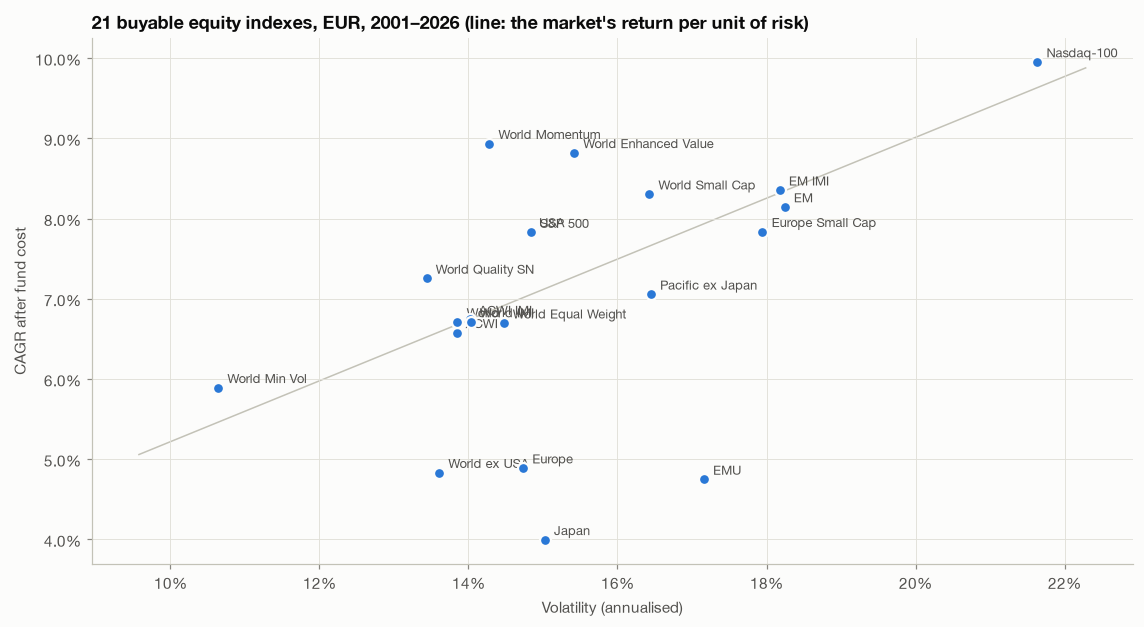

In [5]:
fig, ax = plt.subplots(figsize=(10.5, 5.8))
for c, r_ in SCR.iterrows():
    ax.scatter(r_["Volatility"], r_["CAGR"], s=52, color=SLOT[0], edgecolor=SURFACE, linewidth=1.5, zorder=3)
    ax.annotate(c, (r_["Volatility"], r_["CAGR"]), xytext=(6, 3), textcoords="offset points", fontsize=8.5, color=INK2)
m = SCR.loc["ACWI IMI"]; rfa = rf.mean() * 12
x = np.linspace(SCR["Volatility"].min() * 0.9, SCR["Volatility"].max() * 1.03, 10)
ax.plot(x, rfa + (m["CAGR"] - rfa) / m["Volatility"] * x, color=BASE, lw=1, zorder=1)
ax.xaxis.set_major_formatter(pct0); ax.yaxis.set_major_formatter(pct1)
ax.set_xlabel("Volatility (annualised)"); ax.set_ylabel("CAGR after fund cost")
ax.set_title(f"{len(SCR)} buyable equity indexes, EUR, 2001–2026 (line: the market's return per unit of risk)")
plt.tight_layout(); plt.show()

### 2a · Are any of these differences real?

Every pair is tested (Ledoit–Wolf HAC test on the Sharpe difference), then **Holm-corrected for
the number of pairs**: testing hundreds of pairs at 5% produces a handful of false "differences" by luck alone.

In [6]:
PW = D.pairwise_sharpe(E, rf)
print(f"{len(PW)} pairs tested. Significant at 5% before correction: {(PW['p'] < 0.05).sum()}; "
      f"after Holm correction: {(PW['p (Holm)'] < 0.05).sum()}.")
display(PW.head(8).style.format({"Sharpe A − B": "{:+.2f}", "p": "{:.4f}", "p (Holm)": "{:.2f}"}).hide(axis="index"))
print("The eight most significant pairs. A Holm p below 0.05 would be a difference worth acting on.")

210 pairs tested. Significant at 5% before correction: 10; after Holm correction: 0.


A,B,Sharpe A − B,p,p (Holm)
World Enhanced Value,World ex USA,+0.22,0.0077,1.00
Europe,World Enhanced Value,-0.23,0.0181,1.00
World Momentum,Japan,+0.33,0.0203,1.00
EMU,World Enhanced Value,-0.26,0.0238,1.00
World Momentum,World ex USA,+0.26,0.0302,1.00
ACWI IMI,World ex USA,+0.12,0.0392,1.00
Europe,World Momentum,-0.27,0.0426,1.00
World ex USA,World Equal Weight,-0.11,0.0432,1.00


The eight most significant pairs. A Holm p below 0.05 would be a difference worth acting on.


### 2b · Crises: how deep, how long, and in which months

Fall = worst level reached against the month before the crisis. Recovery = months from the
crisis start until that level is regained (blank = not within the data). For a saver paying in
monthly, a deep but short fall is bought through cheaply; a long one quietly erodes the plan.

In [7]:
CRS = ["GFC 2007-09", "Euro crisis 2011", "COVID 2020", "Inflation 2022"]
cd = D.crisis_detail(E)
det = pd.concat({c: cd.loc[c][["Fall", "Months to recover"]] for c in CRS}, axis=1)
det.columns = [f"{a.split()[0]}: {b.lower().replace('months to ', '')}" for a, b in det.columns]
det = det.loc[SCR.index]
falls = [c for c in det.columns if c.endswith("fall")]
display(det.style.format({c: "{:.1%}" for c in falls} | {c: "{:.0f}" for c in det.columns if "recover" in c}, na_rep="—")
        .background_gradient(cmap="Reds_r", subset=falls, vmin=-0.6, vmax=0))
print("Recovery months are threshold crossings: two near-identical indexes can differ by years if one")
print("misses breakeven by a fraction of a percent. Read them as orders of magnitude.")

,GFC: fall,GFC: recover,Euro: fall,Euro: recover,COVID: fall,COVID: recover,Inflation: fall,Inflation: recover
World Min Vol,-35.6%,50,0.8%,4,-16.4%,17,-6.0%,7
World Quality SN,-43.9%,51,-8.0%,8,-17.8%,10,-15.8%,23
World ex USA,-50.7%,76,-14.4%,16,-21.0%,13,-14.5%,19
ACWI,-48.7%,64,-12.1%,9,-19.7%,10,-13.7%,24
World,-47.6%,63,-11.1%,9,-19.8%,10,-13.5%,19
ACWI IMI,-48.9%,63,-12.7%,9,-20.6%,10,-13.8%,24
World IMI,-47.9%,63,-11.8%,9,-20.7%,10,-13.9%,24
World Momentum,-46.3%,57,-6.5%,7,-15.8%,5,-16.1%,25
World Equal Weight,-50.1%,62,-12.0%,9,-23.7%,11,-14.5%,25
Europe,-53.5%,74,-18.8%,18,-21.6%,14,-17.3%,16


Recovery months are threshold crossings: two near-identical indexes can differ by years if one
misses breakeven by a fraction of a percent. Read them as orders of magnitude.


### 2c · Which properties persist — and are therefore usable for choosing?

Choosing an index is a bet that what you measured in the past continues. So for every property,
split the window in half (2001–2013 / 2014–2026), rank the indexes in each half, and correlate
the two rankings. **A property whose ranking persists can be selected on. One whose ranking
reshuffles is a description of the past, not a guide.**

,"Rank correlation, first half vs second",p,Kind
Volatility,+0.79,0.000,Risk
Beta,+0.27,0.239,Risk
Down capture,+0.43,0.052,Risk
Max drawdown,+0.67,0.001,Risk
Ulcer,-0.16,0.489,Risk
CAGR,-0.52,0.015,Return
Sharpe,-0.57,0.007,Risk-adjusted return
Sortino,-0.55,0.009,Risk-adjusted return
Calmar,-0.60,0.004,Risk-adjusted return


21 indexes, so a rank correlation needs to exceed about ±0.43 to be significant at 5%.


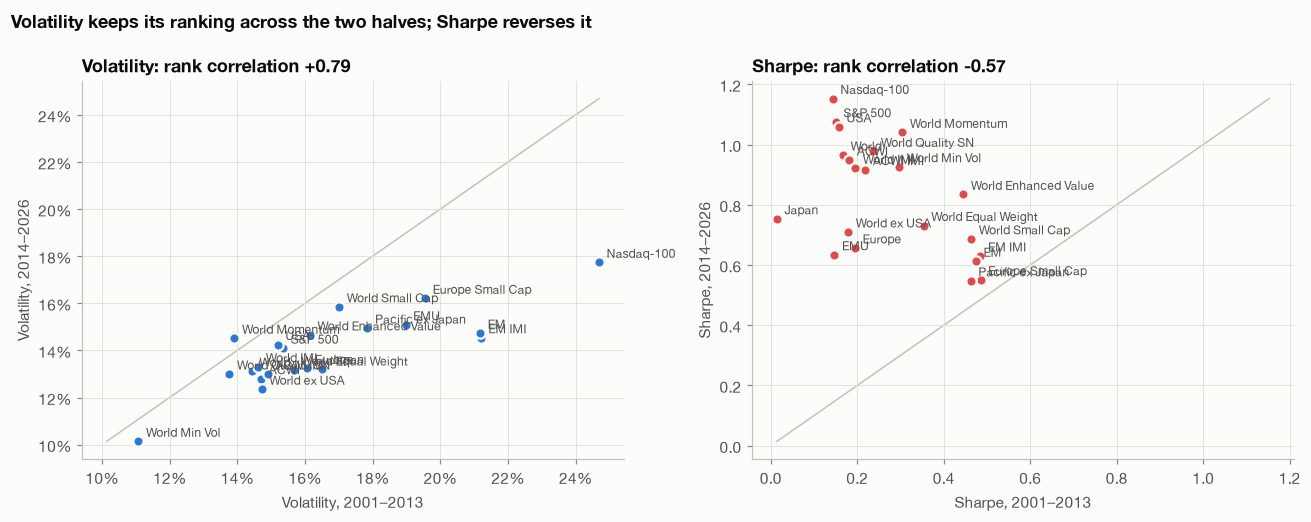

In [8]:
SPLIT = "2013-12"
PROPS = {
    "Volatility": lambda s, m: s.std() * np.sqrt(12),
    "Beta": lambda s, m: D.beta(s, m),
    "Down capture": lambda s, m: D.capture_ratios(s, m)["Down capture"],
    "Max drawdown": lambda s, m: pf.perf_stats(s)["Max drawdown"],
    "Ulcer": lambda s, m: D.ulcer_index(s),
    "CAGR": lambda s, m: pf.perf_stats(s)["CAGR"],
    "Sharpe": lambda s, m: pf.perf_stats(s, 0.0)["Sharpe"],
    "Sortino": lambda s, m: D.downside_stats(s)["Sortino"],
    "Calmar": lambda s, m: D.downside_stats(s)["Calmar"],
}
halves = {"2001–2013": E.loc[:SPLIT], "2014–2026": E.loc["2014-01":]}
per = {h: pd.DataFrame({p: {c: f(x[c].dropna(), x["ACWI IMI"]) for c in x} for p, f in PROPS.items()}) for h, x in halves.items()}
from scipy.stats import spearmanr
pers = pd.DataFrame({p: dict(zip(["Rank correlation, first half vs second", "p"],
                                 spearmanr(per["2001–2013"][p], per["2014–2026"][p])))
                     for p in PROPS}).T
pers["Kind"] = ["Risk"] * 5 + ["Return"] * 1 + ["Risk-adjusted return"] * 3
display(pers.style.format({"Rank correlation, first half vs second": "{:+.2f}", "p": "{:.3f}"})
        .background_gradient(cmap="RdYlGn", subset=["Rank correlation, first half vs second"], vmin=-1, vmax=1))
from scipy.stats import t as tdist
n_ = E.shape[1]; t_ = tdist.ppf(0.975, n_ - 2)
print(f"{n_} indexes, so a rank correlation needs to exceed about ±{t_ / np.sqrt(n_ - 2 + t_**2):.2f} to be significant at 5%.")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, p, col in zip(axes, ["Volatility", "Sharpe"], [SLOT[0], SLOT[5]]):
    a, b = per["2001–2013"][p], per["2014–2026"][p]
    ax.scatter(a, b, s=46, color=col, edgecolor=SURFACE, linewidth=1.5, zorder=3)
    for c in a.index:
        ax.annotate(c, (a[c], b[c]), xytext=(5, 3), textcoords="offset points", fontsize=8, color=INK2)
    lo, hi = min(a.min(), b.min()), max(a.max(), b.max())
    ax.plot([lo, hi], [lo, hi], color=BASE, lw=1, zorder=1)
    ax.set_xlabel(f"{p}, 2001–2013"); ax.set_ylabel(f"{p}, 2014–2026")
    ax.set_title(f"{p}: rank correlation {pers.loc[p].iloc[0]:+.2f}")
    if p == "Volatility":
        ax.xaxis.set_major_formatter(pct0); ax.yaxis.set_major_formatter(pct0)
fig.suptitle("Volatility keeps its ranking across the two halves; Sharpe reverses it", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

**Factor indexes: backtest versus live.** MSCI computes factor indexes back to 1999, but each was
*launched* later; the years before launch were built knowing what had worked. Only the live years
are evidence. Full history from 1999 where it exists; the market is ACWI IMI throughout.

In [9]:
LAUNCH = {"World Min Vol": "2008-06", "World Quality SN": "2014-12", "World Momentum": "2013-12",
          "World Enhanced Value": "2014-08"}
MKT_ALL = EQN["ACWI IMI"]
rows = []
for k, l in LAUNCH.items():
    if k not in EQN:
        continue
    for lab, sl in {"Backtest (before launch)": slice(None, l), "Live (after launch)": slice(l, END)}.items():
        x = EQN[k].loc[sl].dropna(); m_ = MKT_ALL.reindex(x.index)
        rows.append({"Index": k, "Period": lab, "From": x.index[0].strftime("%Y-%m"), "Months": len(x),
                     "Return vs market /yr": (1 + x).prod() ** (12 / len(x)) - (1 + m_).prod() ** (12 / len(x)),
                     "Beta": D.beta(x, m_), "Down capture": D.capture_ratios(x, m_)["Down capture"],
                     "Volatility": x.std() * np.sqrt(12)})
FL = pd.DataFrame(rows)
display(FL.style.format({"Return vs market /yr": "{:+.1%}", "Beta": "{:.2f}", "Down capture": "{:.2f}",
                         "Volatility": "{:.1%}"}).hide(axis="index"))

Index,Period,From,Months,Return vs market /yr,Beta,Down capture,Volatility
World Min Vol,Backtest (before launch),1999-01,114,+0.1%,0.62,0.62,11.3%
World Min Vol,Live (after launch),2008-06,220,-1.2%,0.59,0.48,10.6%
World Quality SN,Backtest (before launch),1999-01,192,+0.4%,0.89,0.90,13.8%
World Quality SN,Live (after launch),2014-12,142,+0.7%,0.96,0.96,13.4%
World Momentum,Backtest (before launch),1999-01,180,+1.4%,0.87,0.87,15.8%
World Momentum,Live (after launch),2013-12,154,+3.4%,0.96,0.90,14.5%
World Enhanced Value,Backtest (before launch),1999-01,188,+4.8%,0.99,0.89,16.1%
World Enhanced Value,Live (after launch),2014-08,146,-0.1%,0.99,1.00,15.0%


**One more trap: the start date.** The window opens in 2001-01, after the Nasdaq-100 had already
lost half its value, so the screen credits it with the recovery and omits most of the crash.

In [10]:
rows = {}
for lab, st in {"from 1999-08": "1999-08", "from the 2000-03 peak": "2000-04", "from 2001-01 (the screen)": "2001-01"}.items():
    for c in ["Nasdaq-100", "S&P 500", "ACWI IMI", "World Min Vol"]:
        s = EQN[c].loc[st:END].dropna()
        rows[(lab, c)] = {"CAGR": pf.perf_stats(s)["CAGR"], "Max drawdown": pf.perf_stats(s)["Max drawdown"],
                          "Longest underwater (m)": pf.perf_stats(s)["Longest underwater (m)"]}
display(pd.DataFrame(rows).T.unstack(0).style.format("{:.1%}", subset=pd.IndexSlice[:, ["CAGR", "Max drawdown"]])
        .format("{:.0f}", subset=pd.IndexSlice[:, ["Longest underwater (m)"]]))

## 3 · The equity shortlist

**What §2 showed.**
- **No Sharpe difference survives.** Of 210 pairs, 10 look significant on their own and none survives once
  the number of pairs is accounted for.
- **Risk-adjusted rankings reverse.** Sharpe, Sortino, Calmar and CAGR rankings in 2001–2013 are
  *negatively* correlated with the rankings in 2014–2026 (−0.52 to −0.60, all significant). The best
  half-window performers tended to become the worst. Choosing on these would be choosing on noise — or worse.
- **Risk rankings persist.** Volatility (+0.79) and maximum drawdown (+0.67) keep their order, both
  with p ≤ 0.001. An index that was less volatile in the first half was less volatile in the second.
- **Of the factor indexes, only min vol kept its defensive character after launch** (beta 0.62 → 0.59,
  down capture 0.62 → 0.48). Quality and momentum drifted to market-like betas (0.96); enhanced value lost
  its +4.8%/yr backtest edge entirely.

**So the shortlist is chosen on what persists — risk and cost — and to cover the real choices**,
not on whichever index topped a ratio. Four questions are genuinely open:

| Candidate | The question it represents | Why this index for it |
|---|---|---|
| **ACWI IMI** and **World** | *Own the whole market* | Two versions of one exposure (correlation 0.99): ACWI IMI adds emerging markets and small caps; World is developed large and mid caps only. Both are carried because their best funds differ in measured cost by 0.13%/yr — about as large as the differences the simulation measures |
| **World Min Vol** | *Accept less return for a smoother ride* | The only defensive index whose lower risk survived launch. ACWI Min Vol cannot be bought |
| **World Momentum** | *Tilt towards recent winners* | Market-like risk (beta 0.96 live), but the one factor whose live return beat its backtest: +3.4%/yr over the market since its 2013 launch, against +1.4% before. Not significant (t ≈ 1.8), and §2c shows return rankings tend to reverse — so it is carried as a bet to be priced, under three return assumptions, not as a finding |
| **S&P 500** | *Concentrate in the US* | The most-bought single-country choice; beta ≈ 1, but one country and one currency. MSCI USA is the same exposure (correlation 0.99) |

**Left out, and why.** Nasdaq-100: beta 1.32 and a −82% fall from its 2000 peak — a leveraged bet on one
sector, not a core holding. Quality SN and Enhanced Value: now market-like risk (beta 0.96–0.99), and
enhanced value lost its backtest edge entirely after launch. Single regions (Europe, EMU, Japan,
Pacific, World ex USA, EM): each is a slice of the market with no persistent compensation for leaving the
rest out. Small caps and equal weight: higher risk with no persistent compensation. They remain in the §2
tables for reference.

In [11]:
SHORT = ["ACWI IMI", "World", "World Min Vol", "World Momentum", "S&P 500"]
sh = SCR.loc[SHORT, ["Fund cost", "CAGR", "Volatility", "Max drawdown", "Ulcer", "Beta", "Down capture", "Up capture", "Sharpe"]]
display(sh.style.format(fmt_scr))
print("Correlations, 2001–2026:")
display(E[SHORT].corr().style.format("{:.2f}"))

,Fund cost,CAGR,Volatility,Max drawdown,Ulcer,Beta,Down capture,Up capture,Sharpe
ACWI IMI,+0.09%,6.7%,14.0%,-49.3%,0.16,1.00,1.00,1.00,0.44
World,-0.04%,6.7%,13.9%,-49.0%,0.18,0.98,0.98,0.99,0.44
World Min Vol,+0.04%,5.9%,10.6%,-39.4%,0.13,0.61,0.55,0.65,0.46
World Momentum,+0.08%,8.9%,14.3%,-46.3%,0.17,0.86,0.85,0.99,0.57
S&P 500,-0.19%,7.8%,14.8%,-55.9%,0.22,1.01,1.00,1.05,0.49


Correlations, 2001–2026:


,ACWI IMI,World,World Min Vol,World Momentum,S&P 500
ACWI IMI,1.00,0.99,0.81,0.85,0.95
World,0.99,1.00,0.83,0.85,0.97
World Min Vol,0.81,0.83,1.00,0.74,0.83
World Momentum,0.85,0.85,0.74,1.00,0.84
S&P 500,0.95,0.97,0.83,0.84,1.00


## 4 · Bond sleeves, judged as partners to each equity candidate

A bond sleeve's job here is not to earn the most on its own but to **cushion the equity sleeve it
sits next to**. So each bond candidate is measured *against* each of the five equity candidates.

**Candidates.** Euro-area government 1-3, 3-7 and 7-10 years, and all maturities (1–30 years, the cheapest funds); US Treasuries hedged to EUR (by
maturity, and all maturities); and a 50/50 blend. All are white-list government bonds, so their gains
are taxed at 12.5% in proportion to the share of white-list bonds the fund certifies (92–100% for the
funds in §6). History runs from 1999: euro-area indexes are rebuilt from the ECB par curve from 2004-10
and from German Bunds before; Treasuries from the US curve, hedged with the short-rate differential.

**Costs.** The rebuilt bond indexes carry a few tenths of a percent a year of modelling error against
real funds — more than a bond fund's fee — so a fund's gap to its *own* rebuild is not its cost. The
*difference* between funds is more reliable, because the modelling error is shared. Over the same
2023–2026 window, hedged Treasury funds trail their rebuilds by 0.10% (Amundi 7-10), 0.37% (Vanguard,
all maturities) and 0.44% (iShares 1-3), ± 0.06–0.09%; euro government funds land between −0.30% and
+0.08%. That puts the **extra cost of hedging at roughly 0.1–0.7%/yr beyond the fee, depending on the
fund**. The simulation uses **0.35%** plus the TER; §4c re-runs it from 0 to 0.9%.

In [12]:
FRICTION = 0.0035
SPL = {"EUR Govt 1-3": "Bund 1-3", "EUR Govt 3-7": "Bund 3-7", "EUR Govt 7-10": "Bund 7-10", "EUR Govt All": "Bund 1-10"}
BCOST = {"EUR Govt 1-3": 0.0010, "EUR Govt 3-7": 0.0015, "EUR Govt 7-10": 0.0015, "EUR Govt All": 0.0007,
         "UST 1-3 (EUR hedged)": 0.0010 + FRICTION, "UST 3-7 (EUR hedged)": 0.0010 + FRICTION,
         "UST 7-10 (EUR hedged)": 0.0010 + FRICTION, "UST All (EUR hedged)": 0.0008 + FRICTION}
BDN = pd.DataFrame({k: D.net_of_cost(pf.splice(bonds[k].dropna(), blong[SPL[k]]) if k in SPL else bonds[k], c)
                    for k, c in BCOST.items()})
BDN["50/50 EUR 3-7 + UST All"] = 0.5 * BDN["EUR Govt 3-7"] + 0.5 * BDN["UST All (EUR hedged)"]
J = pd.concat([EQN[SHORT], BDN], axis=1).loc["1999-02":END]
# MSCI World's EUR history starts 2001-01; the 23 months before are filled with ACWI IMI
# (monthly correlation 0.99) so every simulation keeps the 1999-2026 sample and the dot-com fall.
J["World"] = pf.splice(J["World"].dropna(), J["ACWI IMI"])
J = J.dropna()
rfJ = RF.reindex(J.index).ffill()
print(f"Joint sample {J.index[0]:%Y-%m} → {J.index[-1]:%Y-%m} ({len(J)} months)")

rows = {}
for b in BDN:
    st = D.downside_stats(J[b], rfJ)
    r_ = {"CAGR": st["CAGR"], "Volatility": st["Volatility"], "Max drawdown": st["Max drawdown"],
          "2022": (1 + J[b].loc["2022"]).prod() - 1}
    for e in SHORT:
        worst = J[e] <= J[e].quantile(0.05)
        r_[(e, "Corr.")] = J[b].corr(J[e])
        r_[(e, "Corr. since 2022")] = J[b].loc["2022":].corr(J[e].loc["2022":])
        r_[(e, "In equity's worst 5% months")] = J[b][worst].mean()
    rows[b] = r_
BT = pd.DataFrame(rows).T
own = BT[["CAGR", "Volatility", "Max drawdown", "2022"]]
display(own.style.format("{:.1%}"))
pair = BT[[c for c in BT.columns if isinstance(c, tuple)]]
pair.columns = pd.MultiIndex.from_tuples(pair.columns)
display(pair.style.format("{:+.2f}").format("{:+.1%}", subset=pd.IndexSlice[:, pd.IndexSlice[:, "In equity's worst 5% months"]])
        .background_gradient(cmap="RdYlGn_r", subset=pd.IndexSlice[:, pd.IndexSlice[:, "Corr."]], vmin=-0.4, vmax=0.4)
        .background_gradient(cmap="RdYlGn", subset=pd.IndexSlice[:, pd.IndexSlice[:, "In equity's worst 5% months"]], vmin=-0.02, vmax=0.02))
print("Lower correlation and a higher return in the equity's worst months = a better cushion for that equity sleeve.")

Joint sample 1999-02 → 2026-09 (332 months)


,CAGR,Volatility,Max drawdown,2022
EUR Govt 1-3,1.7%,1.5%,-7.9%,-5.5%
EUR Govt 3-7,2.1%,3.3%,-15.6%,-13.1%
EUR Govt 7-10,2.5%,5.2%,-24.1%,-20.3%
EUR Govt All,2.5%,4.7%,-23.1%,-19.0%
UST 1-3 (EUR hedged),1.5%,1.7%,-10.6%,-6.1%
UST 3-7 (EUR hedged),1.9%,4.2%,-18.1%,-11.4%
UST 7-10 (EUR hedged),2.2%,6.6%,-27.1%,-16.4%
UST All (EUR hedged),2.0%,5.1%,-23.2%,-14.5%
50/50 EUR 3-7 + UST All,2.1%,3.8%,-18.5%,-13.8%


Lower correlation and a higher return in the equity's worst months = a better cushion for that equity sleeve.


,EUR Govt 1-3,EUR Govt 3-7,EUR Govt 7-10,EUR Govt All,UST 1-3 (EUR hedged),UST 3-7 (EUR hedged),UST 7-10 (EUR hedged),UST All (EUR hedged),50/50 EUR 3-7 + UST All
Dot-com 2000-03,16.4%,21.7%,24.8%,21.7%,22.8%,33.2%,37.6%,30.8%,26.2%
GFC 2007-09,8.7%,9.6%,8.7%,8.6%,11.4%,16.5%,19.6%,17.4%,13.5%
Euro crisis 2011,1.2%,3.4%,4.9%,3.8%,1.3%,5.9%,12.0%,9.5%,6.5%
COVID 2020,-0.5%,-1.5%,-3.1%,-2.0%,1.9%,4.3%,6.7%,5.7%,2.1%
Inflation 2022,-4.8%,-11.5%,-18.3%,-17.2%,-6.0%,-11.7%,-16.3%,-14.2%,-12.9%


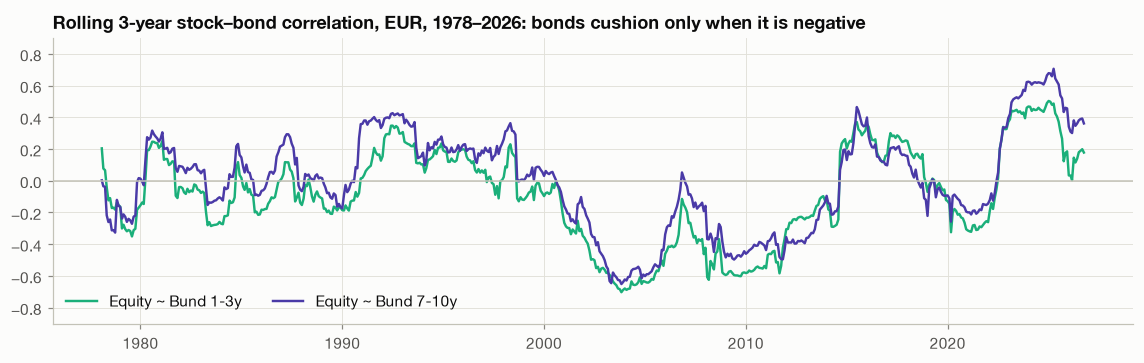

In [13]:
display(D.crisis_table(BDN.loc["1999-02":END]).dropna(how="all").style.format("{:.1%}")
        .background_gradient(cmap="RdYlGn", vmin=-0.3, vmax=0.3, axis=None))

LL = pd.concat([pf.splice(eq["World"].dropna(), L["World blend 60/40"]).rename("Equity"), blong[["Bund 1-3", "Bund 7-10"]]], axis=1).dropna()
rc = pd.DataFrame({k: LL["Equity"].rolling(36).corr(LL[k]) for k in ["Bund 1-3", "Bund 7-10"]}).dropna()
fig, ax = plt.subplots(figsize=(10.5, 3.4))
ax.plot(rc.index, rc["Bund 1-3"], color=SLOT[1], lw=1.6, label="Equity ~ Bund 1-3y")
ax.plot(rc.index, rc["Bund 7-10"], color=SLOT[4], lw=1.6, label="Equity ~ Bund 7-10y")
ax.axhline(0, color=BASE, lw=1); ax.set_ylim(-0.9, 0.9)
ax.set_title("Rolling 3-year stock–bond correlation, EUR, 1978–2026: bonds cushion only when it is negative")
ax.legend(loc="lower left", ncols=2)
plt.tight_layout(); plt.show()

### 4a · What each bond is likely to earn from here

Over a 10-year hold, a bond fund's return is anchored on **today's yield**, not on what bonds did
since 1999 (a period of falling then sharply rising rates). Hedging Treasuries into euros costs the
gap between US and euro short rates, which is currently large.

**Why not 4–5%?** That is what US Treasuries yield (4.5–5.3%), and what the *long* end of the euro curve
and Italian or French 10-year bonds yield (≈ 4.0–4.4%). The candidates here are euro-area government
funds of 1–10 years, all issuers — a mix of Germany at the low end and Italy at the high end — and the
curve is steep: 3.1% at one year, 4.1% at ten. Treasuries lose their extra yield in the hedge.

The simulation uses **the yield, less the fund's fee**. A fund that keeps a constant maturity also
earns **roll-down** while the curve stays as it is: each bond ages towards a shorter, lower-yielding
maturity, and its price rises. On today's steep curve that is worth 0.3–0.6%/yr more. Whether it is
earned depends on rates *not* rising as the curve implies, so it is left out of the base case and
tested in §6f.

In [14]:
YLD = D.current_yields(END)
carry = YLD.attrs["hedge carry"]
EXTRA = (0.0008 + FRICTION) - 0.0012   # hedged UST fund cost + friction, minus a typical euro govt TER
yt = YLD.copy()
yt["Hedged UST minus euro govt"] = yt["US Treasury, EUR hedged"] - yt["Euro govt"]
yt[f"…after the extra cost of hedged funds ({EXTRA:.2%})"] = yt["Hedged UST minus euro govt"] - EXTRA
display(yt.style.format("{:.2%}").format("{:+.2%}", subset=list(yt.columns[-2:])))
print(f"Yields at {END:%Y-%m-%d}. Hedge carry = 1-month Euribor − 3-month T-bill = {carry:+.2%}/yr.")
print("Hedged Treasuries offer no yield advantage today; their case rests entirely on behaviour in crises.")

CURVE = {k: {m: float(s.loc[:END].dropna().iloc[-1]) for m, s in c.items()}
         for k, c in {"Euro govt": D.ea_curve(END), "US Treasury": D.ust_curve(END)}.items()}
cv = pd.DataFrame(CURVE)
cv["US Treasury, EUR hedged"] = cv["US Treasury"] + carry
print("\nThe whole curve, par yield by maturity (years):")
display(cv.T.style.format("{:.2%}", na_rep="—"))
LADDER = {"EUR Govt 1-3": ("Euro govt", [1, 2, 3]), "EUR Govt 3-7": ("Euro govt", [3, 5, 7]),
          "EUR Govt 7-10": ("Euro govt", [7, 10]), "EUR Govt All": ("Euro govt", D.EA_ALL_WEIGHTS),
          "UST All (EUR hedged)": ("US Treasury", D.US_ALL_WEIGHTS)}
ROLL = {k: D.rolldown(CURVE[c], ms if isinstance(ms, dict) else {m: 1 / len(ms) for m in ms})
        for k, (c, ms) in LADDER.items()}
rd = pd.DataFrame({"Yield": {"EUR Govt 1-3": YLD.loc["1-3", "Euro govt"], "EUR Govt 3-7": YLD.loc["3-7", "Euro govt"],
                             "EUR Govt 7-10": YLD.loc["7-10", "Euro govt"], "EUR Govt All": YLD.loc["All maturities", "Euro govt"],
                             "UST All (EUR hedged)": YLD.loc["All maturities", "US Treasury, EUR hedged"]},
                   "Roll-down if the curve stays put": ROLL})
rd["Yield + roll-down"] = rd.sum(axis=1)
display(rd.style.format("{:.2%}"))

,Euro govt,US Treasury,"US Treasury, EUR hedged",Hedged UST minus euro govt,…after the extra cost of hedged funds (0.31%)
1-3,3.26%,4.81%,3.19%,-0.07%,-0.38%
3-7,3.62%,5.09%,3.48%,-0.14%,-0.45%
7-10,3.94%,5.24%,3.62%,-0.32%,-0.63%
All maturities,3.80%,5.13%,3.52%,-0.28%,-0.59%


Yields at 2026-09-30. Hedge carry = 1-month Euribor − 3-month T-bill = -1.62%/yr.
Hedged Treasuries offer no yield advantage today; their case rests entirely on behaviour in crises.



The whole curve, par yield by maturity (years):


,1,2,3,5,7,10,15,20,30
Euro govt,3.06%,3.30%,3.42%,3.62%,3.82%,4.06%,4.31%,4.41%,4.42%
US Treasury,4.54%,4.88%,5.00%,5.09%,5.19%,5.29%,—,5.68%,5.64%
"US Treasury, EUR hedged",2.92%,3.26%,3.38%,3.47%,3.57%,3.67%,—,4.06%,4.02%


,Yield,Roll-down if the curve stays put,Yield + roll-down
EUR Govt 1-3,3.26%,0.35%,3.60%
EUR Govt 3-7,3.62%,0.46%,4.09%
EUR Govt 7-10,3.94%,0.62%,4.57%
EUR Govt All,3.80%,0.42%,4.22%
UST All (EUR hedged),3.52%,0.33%,3.85%


### 4b · Which bond, for each equity candidate? (simulated)

The plan is simulated with each equity candidate paired with each bond candidate, so the bond choice is
made **for that equity sleeve**. The engine and assumptions are set out in full in §5; in short: 5,000
10-year paths drawn in 12-month blocks from 1999–2026, returns re-centred on forward-looking assumptions
(bonds at today's yields after cost), and Italian tax at the end.

To avoid the trap of comparing a riskier portfolio with a safer one, each pair is **dialled to the same
bad-case drawdown** by adjusting its equity weight, and only then compared on the median outcome.

In [15]:
BC = ["EUR Govt 1-3", "EUR Govt 3-7", "EUR Govt 7-10", "EUR Govt All", "UST All (EUR hedged)"]
BOPT = {"Euro govt 1-3": {"EUR Govt 1-3": 1.0}, "Euro govt 3-7": {"EUR Govt 3-7": 1.0},
        "Euro govt 7-10": {"EUR Govt 7-10": 1.0}, "Euro govt all maturities": {"EUR Govt All": 1.0},
        "UST hedged": {"UST All (EUR hedged)": 1.0},
        "50/50 euro 3-7 + UST": {"EUR Govt 3-7": 0.5, "UST All (EUR hedged)": 0.5}}
X = J[SHORT + BC]
B_Y = {"EUR Govt 1-3": YLD.loc["1-3", "Euro govt"], "EUR Govt 3-7": YLD.loc["3-7", "Euro govt"],
       "EUR Govt 7-10": YLD.loc["7-10", "Euro govt"], "EUR Govt All": YLD.loc["All maturities", "Euro govt"],
       "UST All (EUR hedged)": YLD.loc["All maturities", "US Treasury, EUR hedged"]}
EQ_CMA, RF_CMA = 0.063, 0.023    # JPM LTCMA 2026, global equity and EUR cash, compound, EUR
BETA = {e: D.beta(X[e], X["ACWI IMI"]) for e in SHORT}

# Factor sleeves' live record: the multiple of the market's excess return each earned after its index
# launched (index level, before fund cost). Market-like sleeves keep a multiple of 1.
cg = lambda x: (1 + x).prod() ** (12 / len(x)) - 1
LIVE = {}
for k in [e for e in SHORT if e in LAUNCH]:
    x = eq[k].loc[LAUNCH[k]:END].dropna()
    m_, f_ = eq["ACWI IMI"].reindex(x.index), RF.reindex(x.index).ffill()
    LIVE[k] = {"Live since": x.index[0].strftime("%Y-%m"), "Sleeve CAGR": cg(x), "Market CAGR": cg(m_),
               "Cash": cg(f_), "Beta (live)": D.beta(x, m_), "Multiple of market excess return": (cg(x) - cg(f_)) / (cg(m_) - cg(f_))}
LIVE = pd.DataFrame(LIVE).T
S_SAME, S_LIVE, S_BETA = "Same return for every equity sleeve", "Factor sleeves keep their live record", "Equity return priced by beta"
SCN = {S_SAME: "same return", S_LIVE: "live record", S_BETA: "beta-priced"}

def targets(friction=FRICTION):
    bt = {k: B_Y[k] - BCOST[k] + (FRICTION - friction if "UST" in k else 0) for k in BC}
    ec = BEST_EQ["Cost used"]
    same = {e: EQ_CMA for e in SHORT}
    capm = {e: RF_CMA + BETA[e] * (EQ_CMA - RF_CMA) for e in SHORT}
    live = {e: RF_CMA + LIVE.loc[e, "Multiple of market excess return"] * (EQ_CMA - RF_CMA) if e in LIVE.index else EQ_CMA
            for e in SHORT}
    return {s: {**{e: v[e] - ec[e] for e in SHORT}, **bt} for s, v in {S_SAME: same, S_LIVE: live, S_BETA: capm}.items()}

TGT = targets()
H, N = 120, 5000
TAX = np.array([0.26 if c in SHORT else 0.125 for c in X.columns])
PATHS = {s: D.bootstrap_on_targets(X, H, N, 12, seed=41, targets=t) for s, t in TGT.items()}
LIVE["Forward return in the live-record scenario"] = [TGT[S_LIVE][k] + BEST_EQ.loc[k, "Cost used"] for k in LIVE.index]
print("The live-record scenario: each factor sleeve earns the multiple of the market's excess return it earned after launch")
display(LIVE.style.format({**{c: "{:.2%}" for c in LIVE.columns if c not in ("Live since", "Beta (live)", "Multiple of market excess return")},
                           "Beta (live)": "{:.2f}", "Multiple of market excess return": "{:.2f}×"}))
print("Expected compound return per year in each scenario, after fund cost:")
pd.DataFrame(TGT).style.format("{:.2%}")

The live-record scenario: each factor sleeve earns the multiple of the market's excess return it earned after launch


,Live since,Sleeve CAGR,Market CAGR,Cash,Beta (live),Multiple of market excess return,Forward return in the live-record scenario
World Min Vol,2008-06,8.64%,9.93%,0.75%,0.59,0.86×,5.74%
World Momentum,2013-12,15.13%,11.70%,0.63%,0.96,1.31×,7.54%


Expected compound return per year in each scenario, after fund cost:


,Same return for every equity sleeve,Factor sleeves keep their live record,Equity return priced by beta
ACWI IMI,6.21%,6.21%,6.21%
World,6.34%,6.34%,6.28%
World Min Vol,6.26%,5.70%,4.68%
World Momentum,6.22%,7.46%,5.82%
S&P 500,6.49%,6.49%,6.51%
EUR Govt 1-3,3.16%,3.16%,3.16%
EUR Govt 3-7,3.47%,3.47%,3.47%
EUR Govt 7-10,3.79%,3.79%,3.79%
EUR Govt All,3.73%,3.73%,3.73%
UST All (EUR hedged),3.09%,3.09%,3.09%


In [16]:
WG = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]

def wvec(e, we, bmix):
    d = {e: we, **{k: (1 - we) * v for k, v in bmix.items()}}
    return np.array([d.get(c, 0.0) for c in X.columns])

def sweep(paths, e, bmix):
    return [D.outcome_summary(D.pac_paths_rule(paths, wvec(e, we, bmix), TAX, "split"), H) for we in WG]

CURVES = {(s, e, b): sweep(PATHS[s], e, bm) for s in TGT for e in SHORT for b, bm in BOPT.items()}

def rising(x, *ys):
    # risk falls then rises as equity is added (all-bond is not the safest mix): keep the rising branch
    x = np.asarray(x, float); i = int(np.argmin(x))
    return (np.maximum.accumulate(x[i:]),) + tuple(np.asarray(y, float)[i:] for y in ys)

def at_dd(pts, target):
    dd, med, wg = rising([-p["p5 max DD"] for p in pts], [p["Median €"] for p in pts], WG)
    if not dd[0] <= target <= dd[-1]:
        return np.nan, np.nan
    return float(np.interp(target, dd, med)), float(np.interp(target, dd, wg))

DD_T = 0.30
rows = {}
for (s, e, b), pts in CURVES.items():
    med, w = at_dd(pts, DD_T)
    rows[(s, e, b)] = {"Median €": med, "Equity weight needed": w}
BR = pd.DataFrame(rows).T
for s in TGT:
    piv = BR.loc[s]["Median €"].unstack()[list(BOPT)]
    piv = piv.sub(piv.max(axis=1), axis=0)
    print(f"{s} — median after tax at a {DD_T:.0%} bad-case drawdown, € behind the best bond for that equity sleeve:")
    display(piv.style.format("{:+,.0f}").background_gradient(cmap="RdYlGn", vmin=-300, vmax=0, axis=None))
print("Equity weight each pairing needs to reach that drawdown (same-return scenario):")
display(BR.loc[S_SAME]["Equity weight needed"].unstack()[list(BOPT)].style.format("{:.0%}"))

Same return for every equity sleeve — median after tax at a 30% bad-case drawdown, € behind the best bond for that equity sleeve:


,Euro govt 1-3,Euro govt 3-7,Euro govt 7-10,Euro govt all maturities,UST hedged,50/50 euro 3-7 + UST
ACWI IMI,-297,-139,+0,-38,-166,-158
S&P 500,-222,-95,+0,-31,-105,-100
World,-262,-119,+0,-55,-150,-130
World Min Vol,-169,-86,+0,-40,-95,-98
World Momentum,-305,-161,+0,-62,-224,-172


Factor sleeves keep their live record — median after tax at a 30% bad-case drawdown, € behind the best bond for that equity sleeve:


,Euro govt 1-3,Euro govt 3-7,Euro govt 7-10,Euro govt all maturities,UST hedged,50/50 euro 3-7 + UST
ACWI IMI,-297,-139,+0,-38,-166,-158
S&P 500,-222,-95,+0,-31,-105,-100
World,-262,-119,+0,-55,-150,-130
World Min Vol,-167,-88,+0,-32,-104,-109
World Momentum,-293,-139,+0,-68,-188,-153


Equity return priced by beta — median after tax at a 30% bad-case drawdown, € behind the best bond for that equity sleeve:


,Euro govt 1-3,Euro govt 3-7,Euro govt 7-10,Euro govt all maturities,UST hedged,50/50 euro 3-7 + UST
ACWI IMI,-297,-139,+0,-38,-166,-158
S&P 500,-223,-95,+0,-32,-105,-101
World,-261,-121,+0,-52,-152,-131
World Min Vol,-163,-85,+0,-20,-129,-120
World Momentum,-309,-168,+0,-66,-240,-188


Equity weight each pairing needs to reach that drawdown (same-return scenario):


,Euro govt 1-3,Euro govt 3-7,Euro govt 7-10,Euro govt all maturities,UST hedged,50/50 euro 3-7 + UST
ACWI IMI,53%,54%,52%,52%,57%,56%
S&P 500,53%,53%,52%,52%,57%,55%
World,53%,53%,52%,52%,57%,55%
World Min Vol,68%,69%,69%,69%,73%,71%
World Momentum,49%,49%,47%,47%,51%,50%


**7-10 years or all maturities?** The all-maturity funds are the cheapest bond funds on the list
(0.05–0.07% against 0.15%), the largest, and the ones with a verified white-list share for the 12.5% rate.
They hold the whole curve, 1 to 30 years, at about the same duration as 7-10 (6.8 against 7.1). Below, the
two head to head: matched risk, every equity sleeve, all three return scenarios, on the yield alone and
with roll-down (§4a) added. Then the real funds on their common history.

In [17]:
h2h = {}
for roll in (False, True):
    for s, t in TGT.items():
        t_ = {k: v + (ROLL.get(k, 0) if roll else 0) for k, v in t.items()}
        P_ = PATHS[s] if not roll else D.bootstrap_on_targets(X, H, N, 12, seed=41, targets=t_)
        for e in SHORT:
            m = {b: at_dd(CURVES[(s, e, b)] if not roll else sweep(P_, e, BOPT[b]), tt)[0]
                 for b in ("Euro govt 7-10", "Euro govt all maturities") for tt in [0.35]}
            h2h[("Yield + roll-down" if roll else "Yield only", SCN[s], e)] = m["Euro govt all maturities"] - m["Euro govt 7-10"]
H2H = pd.Series(h2h).unstack()[SHORT]
print("All maturities minus 7-10, median after tax at a 35% bad-case drawdown (negative = 7-10 better):")
display(H2H.style.format("{:+,.0f} €").background_gradient(cmap="RdYlGn", vmin=-300, vmax=300, axis=None))

rf_ = {}
for f in ETF.records(ETF.BOND):
    if f["index"] in ("EUR Govt 7-10", "EUR Govt All", "EUR Govt 3-7") and f["ticker"] != "DBXQ.DE":
        try:
            rf_[f"{f['ticker'].split('.')[0]} ({f['index'].replace('EUR Govt ', '')}, {f['ter']:.2%})"] = D.etf_returns(f["ticker"], END, f["start"])
        except Exception:
            pass
RFD = pd.DataFrame(rf_).loc[:END].dropna()
fs = pd.DataFrame({"CAGR": (1 + RFD).prod() ** (12 / len(RFD)) - 1, "Volatility": RFD.std() * np.sqrt(12),
                   "2022": (1 + RFD.loc["2022"]).prod() - 1,
                   "Max drawdown": RFD.apply(lambda r: pf.perf_stats(r)["Max drawdown"])})
print(f"Real funds, common history {RFD.index[0]:%Y-%m} → {RFD.index[-1]:%Y-%m} (a period of rising rates):")
display(fs.style.format("{:.1%}"))

All maturities minus 7-10, median after tax at a 35% bad-case drawdown (negative = 7-10 better):


Real funds, common history 2020-05 → 2026-09 (a period of rising rates):


,CAGR,Volatility,2022,Max drawdown
"SXRP (3-7, 0.15%)",-0.7%,4.0%,-12.1%,-13.8%
"X710 (7-10, 0.15%)",-2.3%,6.8%,-19.9%,-22.3%
"SXRQ (7-10, 0.15%)",-2.3%,6.8%,-19.9%,-22.4%
"VGEA (All, 0.07%)",-2.2%,6.0%,-18.3%,-21.5%
"XGLE (All, 0.07%)",-2.2%,6.1%,-18.4%,-21.6%
"PRAR (All, 0.05%)",-2.0%,6.1%,-18.2%,-21.3%


### 4c · How much does the bond verdict depend on the cost of hedging?

The one uncertain input is the hedging friction on Treasuries. Re-run with the friction at zero,
at the middle estimate, and at the top of the measured range.

In [18]:
fr_rows = {}
for fr in (0.0, FRICTION, 0.0090):
    T_ = targets(fr)[S_SAME]
    P_ = D.bootstrap_on_targets(X, H, 3000, 12, seed=43, targets=T_)
    for e in SHORT:
        meds = {b: at_dd(sweep(P_, e, bm), DD_T)[0] for b, bm in BOPT.items()}
        best_eur = max(meds[b] for b in BOPT if b.startswith("Euro"))
        fr_rows[(f"{fr:.2%}", e)] = {"UST hedged vs best euro govt": meds["UST hedged"] - best_eur,
                                     "50/50 vs best euro govt": meds["50/50 euro 3-7 + UST"] - best_eur}
display(pd.DataFrame(fr_rows).T.rename_axis(["Hedging friction", "Equity sleeve"]).style.format("{:+,.0f} €")
        .background_gradient(cmap="RdYlGn", vmin=-300, vmax=300, axis=None))
print(f"Positive = hedged Treasuries beat the best euro government sleeve at the same {DD_T:.0%} bad-case drawdown.")

Positive = hedged Treasuries beat the best euro government sleeve at the same 30% bad-case drawdown.


**And in an inflationary regime?** 1999–2026 is mostly a period of negative stock–bond correlation, which
flatters long bonds. Below, broad equity with euro government bonds (German Bunds before 2004) over
**1975–2026**, and then **only the months when the stock–bond correlation was positive** (the 1970s–90s
and 2022–) — the regime in which long bonds stop cushioning.

In [19]:
eqLong = D.net_of_cost(pf.splice(eq["ACWI IMI"].dropna(), L["World blend 60/40"]), BEST_EQ.loc["ACWI IMI", "Cost used"])
XL = pd.DataFrame({"Equity": eqLong, **{k: BDN[k] for k in BC[:4]}}).loc[:END].dropna()
TL = {"Equity": EQ_CMA - BEST_EQ.loc["ACWI IMI", "Cost used"], **{k: B_Y[k] - BCOST[k] for k in BC[:4]}}
TAXL = np.array([0.26, 0.125, 0.125, 0.125, 0.125])
corr36 = XL["Equity"].rolling(36).corr(XL["EUR Govt 3-7"])
REG = {"1975–2026, all months": (XL, 12), "1975–2026, positive stock–bond correlation only": (XL.loc[corr36 > 0.2], 6)}
rows = {}
for lab, (S_, blk) in REG.items():
    P_ = D.bootstrap_on_targets(S_, H, 3000, blk, seed=7, targets=TL)
    for b in BC[:4]:
        pts = [D.outcome_summary(D.pac_paths_rule(P_, np.array([we] + [(1 - we) if c == b else 0 for c in BC[:4]]), TAXL, "split"), H)
               for we in WG]
        rows[(lab, b)] = {f"Median at {t:.0%} drawdown": at_dd(pts, t)[0] for t in (0.25, 0.30, 0.35)} | {"Months": len(S_)}
RG = pd.DataFrame(rows).T
display(RG.style.format(EUR0([c for c in RG.columns if c.startswith("Median")]) | {"Months": "{:.0f}"}))

### 4d · The bond verdict

- **Euro-area government bonds beat hedged Treasuries at equal risk, for every equity sleeve, under all three
  return assumptions — and still beat them if hedging cost nothing beyond the fund fee.** The
  reason is today's yields: hedging dollars into euros currently costs the 1.6-point gap between US and
  euro short rates, which wipes out the higher Treasury yield. Hedged Treasuries yield 0.1–0.3 points
  *less* than euro government bonds of similar maturity before any friction.
- **Hedged Treasuries are still the better crash cushion** — +17% in the GFC against +9–10% for euro
  bonds, +6% in COVID against −1 to −3%, and a correlation with equities of about −0.3 instead of ≈ 0.
  In 2022 they did no better than euro bonds of similar duration. The simulation already counts that
  cushioning, and it is not enough to pay for the lower yield. **This reverses the previous notebook's
  finding**, which assumed 3.4% for hedged Treasuries against 3.1% for euro 3-7 instead of using today's
  yields after cost.
- **Among euro maturities, longer is better at matched risk, but by little.** 7-10 years beats 3-7 by
  €85–170 and 1-3 by €165–310 at a 30% bad-case drawdown. The edge comes from the higher yield and
  shrinks, but holds, when only positive-correlation months are used. The price is a larger loss in an
  inflation shock: −18% in 2022 against −12% for 3-7.
- **All maturities is a near-tie with 7-10.** It ends €15–60 behind at matched risk on the yield alone,
  €55–145 behind if roll-down is counted. Two reasons: about a fifth of the fund sits in 15–30-year bonds
  on a flat part of the curve (4.3–4.4%), which adds rate risk for little extra yield or roll-down; and
  its lower fee (0.05–0.07% vs 0.15%) only partly makes up for it. The real funds since 2020 confirm the
  two behave alike (correlation 0.99; 2022 −18% vs −20%). Its advantages are practical: the lowest fees,
  the largest funds, and a **verified** white-list share (Vanguard 99.5%, Amundi 99.9%), which the 7-10
  funds lack. If the 7-10 fund's share turned out materially lower, all maturities would be the better choice.

**Carried forward:** **Euro govt 7-10** (best outcome at equal risk) and **US Treasuries hedged** (best
cushion in a deflationary crash, at a known cost). Euro govt all maturities is an equivalent substitute
for 7-10, and euro govt 3-7 is a reasonable compromise if a 2022-style bond loss weighs more than the €85–170.

## 5 · Weights

Ten portfolios: each of the five equity candidates with each of the two bond candidates carried from §4. For each, the equity weight is
chosen from four angles: risk-adjusted ratios on history, crisis replay, stress tests, and a
simulation of the actual plan after Italian tax.

### 5a · Can history pick the weight? (Sharpe, Sortino, Calmar)

For each portfolio, the weight that maximised each ratio over 1999–2026 — and, by resampling that
history 500 times, how much that "optimal" weight moves.

In [20]:
BOND2 = {"Euro govt 7-10": "EUR Govt 7-10", "UST hedged": "UST All (EUR hedged)"}
PORTS = {f"{e} + {bl}": (e, b) for e in SHORT for bl, b in BOND2.items()}
GR = np.round(np.arange(0.3, 1.001, 0.05), 2)
rows = {}
for name, (e, b) in PORTS.items():
    st = {}
    for we in GR:
        p = we * J[e] + (1 - we) * J[b]
        s = D.downside_stats(p, rfJ)
        st[we] = {"Sharpe": s["Sharpe"], "Sortino": s["Sortino"], "Calmar": s["Calmar"]}
    st = pd.DataFrame(st).T
    bw = D.best_weight_boot(J[e], J[b], rfJ, GR, n=500, seed=3)
    for m in ["Sharpe", "Sortino", "Calmar"]:
        rows[(name, m)] = {"Best weight on 1999–2026": st[m].idxmax(),
                           "Resampled: 10th pct": bw[m].quantile(0.1), "median": bw[m].median(),
                           "90th pct": bw[m].quantile(0.9)}
BW = pd.DataFrame(rows).T
display(BW.style.format("{:.0%}"))
print("The ratios cannot choose the weight: on resampled histories the 'best' weight ranges over most of 30–100%.")

The ratios cannot choose the weight: on resampled histories the 'best' weight ranges over most of 30–100%.


### 5b · Crisis replay at every weight

Lump-sum, rebalanced monthly, through each real crisis since 1999 — and the deepest fall and longest
time under water over the whole period.

In [21]:
CW = [1.0, 0.8, 0.6]
rep = {}
for name, (e, b) in PORTS.items():
    for we in CW:
        p = we * J[e] + (1 - we) * J[b]
        col = {k: v for k, v in D.crisis_table(p.to_frame("x"))["x"].dropna().items()}
        st = pf.perf_stats(p)
        col |= {"Max drawdown 1999–2026": st["Max drawdown"], "Longest underwater (months)": st["Longest underwater (m)"],
                "CAGR 1999–2026": st["CAGR"]}
        rep[(name, f"{we:.0%}")] = col
REP = pd.DataFrame(rep)
rowsfmt = [r for r in REP.index if r != "Longest underwater (months)"]
display(REP.style.format("{:.1%}", subset=pd.IndexSlice[rowsfmt, :]).format("{:.0f}", subset=pd.IndexSlice[["Longest underwater (months)"], :])
        .background_gradient(cmap="RdYlGn", vmin=-0.5, vmax=0.3, axis=None, subset=pd.IndexSlice[rowsfmt[:-1], :]))

### 5c · The plan, simulated, at every weight

5,000 paths of the actual plan (€1,000 + €100/month for 10 years, €1 on the first order, 0.2% stamp duty,
everything sold at year 10 and taxed at 26% equity / 12.5% bonds). History 1999–2026 supplies the shapes
and correlations, drawn in 12-month blocks so crises stay intact. Returns are re-centred on:

- **Equity:** 6.3%/yr for global equity (JPM 2026, EUR), after each fund's measured cost. Three versions,
  because what the two factor sleeves will earn is genuinely unknown; the market-like sleeves get about the
  same number in all three:
  - *Same return for every equity sleeve* — min vol and momentum earn the market's 6.3%. For min vol that is
    the "low-volatility anomaly" (low-risk stocks earned about the market return over long histories); for
    momentum it assumes its premium is gone.
  - *Factor sleeves keep their live record* — each factor sleeve earns the multiple of the market's excess
    return that it earned after its index launched (table in §4b): min vol less than the market, momentum
    more.
  - *Priced by beta* — cash + beta × (market − cash): you are paid only for market risk. Min vol, with beta
    ≈ 0.6, expects about 4.7%; momentum, with beta ≈ 0.9, slightly less than the market.
- **Bonds:** today's yield after fund cost (and hedging friction for Treasuries). See §4a for why this is
  3.2–3.9% and not 4–5%.

The **bad-case drawdown** is the 5th-percentile worst fall of the account relative to what has been paid
in — the number to compare with what you could sit through without selling.

In [22]:
WS = [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
SIM = {}
for s in TGT:
    for name, (e, b) in PORTS.items():
        for we in WS:
            SIM[(s, name, f"{we:.0%}")] = D.outcome_summary(D.pac_paths_rule(PATHS[s], wvec(e, we, {b: 1.0}), TAX, "split"), H)
SIMT = pd.DataFrame(SIM).T
SIMT.index.names = ["Scenario", "Portfolio", "Equity"]
SC = ["Median €", "Bad case p5 €", "P(end < paid in)", "Median IRR", "p5 max DD"]
for s in TGT:
    print(f"{s}  (€13,000 paid in)")
    display(SIMT.loc[s][SC].unstack("Equity")["Median €"][[f"{w:.0%}" for w in WS]]
            .style.format("€{:,.0f}").background_gradient(cmap="Greens", axis=None))
print("Bad case (5th percentile) € — same-return scenario:")
display(SIMT.loc[S_SAME]["Bad case p5 €"].unstack("Equity")[[f"{w:.0%}" for w in WS]]
        .style.format("€{:,.0f}").background_gradient(cmap="RdYlGn", axis=None))
print("Bad-case drawdown of the account — same-return scenario:")
display(SIMT.loc[S_SAME]["p5 max DD"].unstack("Equity")[[f"{w:.0%}" for w in WS]]
        .style.format("{:.0%}").background_gradient(cmap="RdYlGn", axis=None))

Same return for every equity sleeve  (€13,000 paid in)


Equity,50%,60%,70%,80%,90%,100%
Portfolio,,,,,,
ACWI IMI + Euro govt 7-10,"€16,475","€16,650","€16,826","€17,020","€17,210","€17,411"
ACWI IMI + UST hedged,"€16,190","€16,416","€16,637","€16,886","€17,158","€17,411"
S&P 500 + Euro govt 7-10,"€16,552","€16,806","€17,030","€17,270","€17,535","€17,769"
S&P 500 + UST hedged,"€16,313","€16,592","€16,882","€17,179","€17,481","€17,769"
World + Euro govt 7-10,"€16,527","€16,725","€16,961","€17,180","€17,389","€17,593"
World + UST hedged,"€16,248","€16,507","€16,789","€17,065","€17,317","€17,593"
World Min Vol + Euro govt 7-10,"€16,327","€16,479","€16,661","€16,828","€17,005","€17,204"
World Min Vol + UST hedged,"€16,068","€16,263","€16,491","€16,726","€16,960","€17,204"
World Momentum + Euro govt 7-10,"€16,532","€16,724","€16,932","€17,159","€17,349","€17,572"


Factor sleeves keep their live record  (€13,000 paid in)


Equity,50%,60%,70%,80%,90%,100%
Portfolio,,,,,,
ACWI IMI + Euro govt 7-10,"€16,475","€16,650","€16,826","€17,020","€17,210","€17,411"
ACWI IMI + UST hedged,"€16,190","€16,416","€16,637","€16,886","€17,158","€17,411"
S&P 500 + Euro govt 7-10,"€16,552","€16,806","€17,030","€17,270","€17,535","€17,769"
S&P 500 + UST hedged,"€16,313","€16,592","€16,882","€17,179","€17,481","€17,769"
World + Euro govt 7-10,"€16,527","€16,725","€16,961","€17,180","€17,389","€17,593"
World + UST hedged,"€16,248","€16,507","€16,789","€17,065","€17,317","€17,593"
World Min Vol + Euro govt 7-10,"€16,109","€16,228","€16,361","€16,491","€16,626","€16,782"
World Min Vol + UST hedged,"€15,863","€16,010","€16,201","€16,387","€16,575","€16,782"
World Momentum + Euro govt 7-10,"€17,029","€17,342","€17,653","€17,967","€18,276","€18,584"


Equity return priced by beta  (€13,000 paid in)


Equity,50%,60%,70%,80%,90%,100%
Portfolio,,,,,,
ACWI IMI + Euro govt 7-10,"€16,475","€16,650","€16,826","€17,020","€17,210","€17,411"
ACWI IMI + UST hedged,"€16,190","€16,416","€16,637","€16,886","€17,158","€17,411"
S&P 500 + Euro govt 7-10,"€16,561","€16,816","€17,042","€17,282","€17,549","€17,785"
S&P 500 + UST hedged,"€16,321","€16,602","€16,893","€17,192","€17,496","€17,785"
World + Euro govt 7-10,"€16,501","€16,693","€16,926","€17,141","€17,345","€17,543"
World + UST hedged,"€16,222","€16,475","€16,752","€17,024","€17,272","€17,543"
World Min Vol + Euro govt 7-10,"€15,742","€15,792","€15,845","€15,901","€15,966","€16,048"
World Min Vol + UST hedged,"€15,499","€15,580","€15,691","€15,799","€15,922","€16,048"
World Momentum + Euro govt 7-10,"€16,381","€16,536","€16,711","€16,909","€17,065","€17,273"


Bad case (5th percentile) € — same-return scenario:


Equity,50%,60%,70%,80%,90%,100%
Portfolio,,,,,,
ACWI IMI + Euro govt 7-10,"€13,051","€12,574","€12,004","€11,439","€10,768","€10,105"
ACWI IMI + UST hedged,"€13,359","€12,794","€12,172","€11,491","€10,804","€10,105"
S&P 500 + Euro govt 7-10,"€13,022","€12,515","€11,950","€11,335","€10,734","€10,087"
S&P 500 + UST hedged,"€13,337","€12,752","€12,103","€11,443","€10,761","€10,087"
World + Euro govt 7-10,"€13,070","€12,550","€11,970","€11,312","€10,646","€10,092"
World + UST hedged,"€13,398","€12,760","€12,096","€11,376","€10,715","€10,092"
World Min Vol + Euro govt 7-10,"€13,480","€13,284","€12,939","€12,584","€12,090","€11,677"
World Min Vol + UST hedged,"€13,707","€13,433","€13,078","€12,660","€12,190","€11,677"
World Momentum + Euro govt 7-10,"€12,692","€12,137","€11,505","€10,846","€10,197","€9,580"


Bad-case drawdown of the account — same-return scenario:


Equity,50%,60%,70%,80%,90%,100%
Portfolio,,,,,,
ACWI IMI + Euro govt 7-10,-29%,-34%,-40%,-45%,-51%,-57%
ACWI IMI + UST hedged,-26%,-32%,-38%,-44%,-51%,-57%
S&P 500 + Euro govt 7-10,-29%,-34%,-40%,-46%,-51%,-57%
S&P 500 + UST hedged,-26%,-32%,-38%,-45%,-51%,-57%
World + Euro govt 7-10,-29%,-34%,-40%,-46%,-51%,-57%
World + UST hedged,-26%,-32%,-38%,-45%,-51%,-57%
World Min Vol + Euro govt 7-10,-21%,-26%,-30%,-35%,-40%,-45%
World Min Vol + UST hedged,-19%,-23%,-29%,-34%,-39%,-45%
World Momentum + Euro govt 7-10,-31%,-37%,-43%,-48%,-54%,-60%


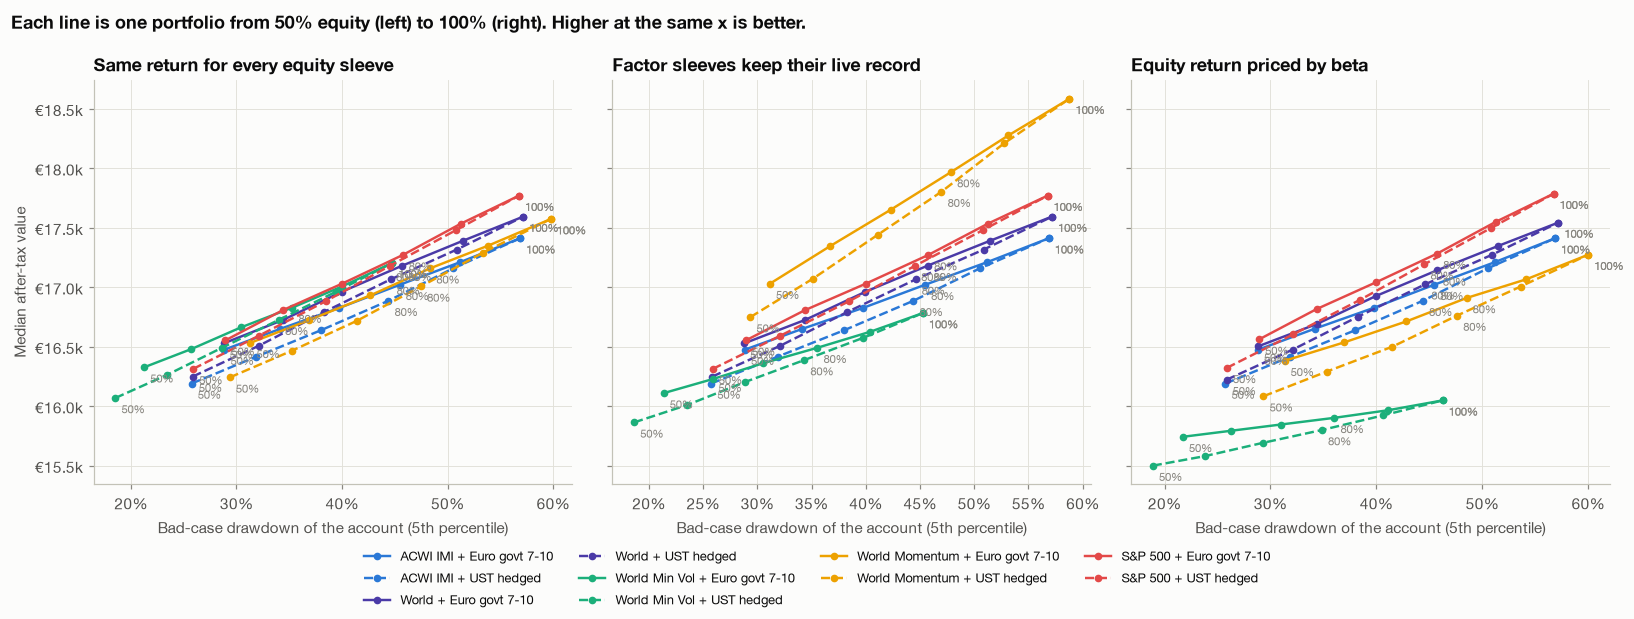

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5.6), sharey=True)
pcol = {"ACWI IMI": SLOT[0], "World": SLOT[4], "World Min Vol": SLOT[1], "World Momentum": SLOT[2], "S&P 500": SLOT[5]}
for ax, s in zip(axes, TGT):
    for name, (e, b) in PORTS.items():
        sub = SIMT.loc[(s, name)]
        ls = "-" if b.startswith("EUR") else "--"
        ax.plot(-sub["p5 max DD"], sub["Median €"], color=pcol[e], ls=ls, marker="o", ms=4, lw=1.6, label=name)
        for w_ in ("50%", "80%", "100%"):
            ax.annotate(w_, (-sub.loc[w_, "p5 max DD"], sub.loc[w_, "Median €"]), xytext=(4, -10),
                        textcoords="offset points", fontsize=7.5, color=MUTED)
    ax.xaxis.set_major_formatter(pct0); ax.yaxis.set_major_formatter(eur_k)
    ax.set_xlabel("Bad-case drawdown of the account (5th percentile)"); ax.set_title(s)
axes[0].set_ylabel("Median after-tax value")
h_, l_ = axes[0].get_legend_handles_labels()
fig.legend(h_, l_, loc="lower center", ncols=4, fontsize=8.5)
fig.suptitle("Each line is one portfolio from 50% equity (left) to 100% (right). Higher at the same x is better.",
             x=0.01, ha="left", fontweight="bold")
plt.tight_layout(rect=(0, 0.1, 1, 1)); plt.show()

### 5d · Stress tests

The same simulation, deliberately pushed against the portfolios: only the months when stocks and bonds
moved together (bonds stop helping); short and long blocks (crises shorter or more persistent); and the
plan run through **every actual 10-year window since 1999** instead of resampled ones — including the one
that started at the top of the dot-com bubble.

In [24]:
STRESS_W = [0.6, 0.8]
T0 = TGT[S_SAME]
corrJ = J["ACWI IMI"].rolling(36).corr(J["EUR Govt 7-10"])
Xpos = X.loc[corrJ.reindex(X.index) > 0.2]
STR = {"Positive stock–bond correlation months only": D.bootstrap_on_targets(Xpos, H, 3000, 6, seed=21, targets=T0),
       "Short blocks (3 months)": D.bootstrap_on_targets(X, H, 3000, 3, seed=22, targets=T0),
       "Long blocks (24 months)": D.bootstrap_on_targets(X, H, 3000, 24, seed=23, targets=T0)}
rows = {}
for lab, P_ in STR.items():
    for name, (e, b) in PORTS.items():
        for we in STRESS_W:
            o = D.outcome_summary(D.pac_paths_rule(P_, wvec(e, we, {b: 1.0}), TAX, "split"), H)
            rows[(lab, name, f"{we:.0%}")] = {"Median €": o["Median €"], "Bad case p5 €": o["Bad case p5 €"],
                                              "P(end < paid in)": o["P(end < paid in)"], "p5 max DD": o["p5 max DD"]}
ST = pd.DataFrame(rows).T
print(f"Positive-correlation subsample: {len(Xpos)} months. Same-return scenario throughout.")
display(ST["Bad case p5 €"].unstack([2]).unstack(0).style.format("€{:,.0f}").background_gradient(cmap="RdYlGn", axis=None))

Positive-correlation subsample: 93 months. Same-return scenario throughout.


In [25]:
Wh, starts = D.historical_windows(X, 10)
rows = {}
for name, (e, b) in PORTS.items():
    for we in STRESS_W:
        res = D.pac_paths_rule(Wh, wvec(e, we, {b: 1.0}), TAX, "split")
        o = D.outcome_summary(res, H)
        i = int(np.argmin(res["after_tax"]))
        rows[(name, f"{we:.0%}")] = {"Median €": o["Median €"], "Worst €": res["after_tax"].min(),
                                     "Worst start": starts[i].strftime("%Y-%m"),
                                     "P(end < paid in)": o["P(end < paid in)"], "Worst drawdown": res["max_dd"].min()}
print(f"Actual history, no re-centring: {len(starts)} overlapping 10-year windows starting {starts[0]:%Y-%m} … {starts[-1]:%Y-%m}.")
display(pd.DataFrame(rows).T.style.format(EUR0(["Median €", "Worst €"]) | P1(["P(end < paid in)", "Worst drawdown"])))

Actual history, no re-centring: 213 overlapping 10-year windows starting 1999-02 … 2016-10.


### 5e · Choosing the weight: a risk budget

§5a shows history cannot pin the weight down, and the optimisers of the previous notebook agreed: the
equity weight is **a choice of how deep a fall you can sit through without selling**, not something to
be estimated. So the table below turns it round: pick the bad-case drawdown you can tolerate, and read
off the equity weight each portfolio needs and what it is expected to deliver.

In [26]:
RB = {}
for s in TGT:
    for name, (e, b) in PORTS.items():
        pts = sweep(PATHS[s], e, {b: 1.0})
        dd, wg = rising([-p["p5 max DD"] for p in pts], WG)
        for t in (0.25, 0.30, 0.35, 0.40):
            if dd[0] <= t <= dd[-1]:
                w = float(np.interp(t, dd, wg))
                o = D.outcome_summary(D.pac_paths_rule(PATHS[s], wvec(e, w, {b: 1.0}), TAX, "split"), H)
                RB[(f"{t:.0%}", s, name)] = {"Equity weight": w, "Median €": o["Median €"], "Bad case p5 €": o["Bad case p5 €"],
                                             "P(end < paid in)": o["P(end < paid in)"], "Median IRR": o["Median IRR"]}
            else:
                RB[(f"{t:.0%}", s, name)] = {"Equity weight": np.nan}
RBT = pd.DataFrame(RB).T
RBT.index.names = ["Tolerable bad-case drawdown", "Scenario", "Portfolio"]
display(RBT.style.format({"Equity weight": "{:.0%}", "Median €": "€{:,.0f}", "Bad case p5 €": "€{:,.0f}",
                          "P(end < paid in)": "{:.1%}", "Median IRR": "{:.2%}"}, na_rep="beyond reach"))

,,,Equity weight,Median €,Bad case p5 €,P(end < paid in),Median IRR
Tolerable bad-case drawdown,Scenario,Portfolio,,,,,
25%,Same return for every equity sleeve,ACWI IMI + Euro govt 7-10,42%,"€16,370","€13,341",3.2%,4.25%
30%,Same return for every equity sleeve,ACWI IMI + Euro govt 7-10,52%,"€16,521","€12,922",5.3%,4.41%
35%,Same return for every equity sleeve,ACWI IMI + Euro govt 7-10,61%,"€16,680","€12,505",7.7%,4.59%
40%,Same return for every equity sleeve,ACWI IMI + Euro govt 7-10,70%,"€16,839","€11,981",9.9%,4.76%
25%,Same return for every equity sleeve,ACWI IMI + UST hedged,49%,"€16,157","€13,425",2.7%,4.01%
30%,Same return for every equity sleeve,ACWI IMI + UST hedged,57%,"€16,354","€12,994",5.1%,4.23%
35%,Same return for every equity sleeve,ACWI IMI + UST hedged,65%,"€16,528","€12,490",7.8%,4.42%
40%,Same return for every equity sleeve,ACWI IMI + UST hedged,73%,"€16,712","€11,967",10.0%,4.62%
25%,Same return for every equity sleeve,World + Euro govt 7-10,43%,"€16,406","€13,367",3.1%,4.29%


### 5e-bis · Does the verdict depend on measuring risk by drawdown?

Everything above matches portfolios on one risk measure, the bad-case drawdown. Below, the same euro-govt
portfolios are matched on **seven other measures**, each set to the level the 35%-drawdown World portfolio
reaches, and compared on the median. If the ranking held only for drawdown, it would be an artefact of the
measure.

| Measure | What it captures |
|---|---|
| Volatility (simulated / 1999–2026) | Month-to-month swings — the textbook risk measure |
| Bad case € (5th percentile) | How little you could end with |
| CVaR 5% € | The *average* of the worst 5% of endings — the depth of the tail, not just its edge |
| P(end < paid in) | The chance of losing money in nominal terms |
| P(real loss) | The chance of ending below the contributions grown at 2% inflation |
| Max drawdown 1999–2026 | The worst fall the mix actually suffered |

Then a **different kind of comparison**, which avoids choosing a risk level at all: the *certainty
equivalent* — the sure amount an investor would swap the uncertain outcome for. γ is risk aversion: at γ = 2
a bad path counts a little more than a good one; at γ = 8 the worst paths dominate. Each portfolio is shown
at its best weight for that investor.

In [27]:
FINE = np.round(np.arange(0.2, 1.001, 0.05), 2)
SWEEP = {}
for s in TGT:
    for e in SHORT:
        for we in FINE:
            o = D.outcome_summary(D.pac_paths_rule(PATHS[s], wvec(e, we, {"EUR Govt 7-10": 1.0}), TAX, "split"), H)
            p = we * J[e] + (1 - we) * J["EUR Govt 7-10"]
            SWEEP[(s, e, we)] = {**o, "Hist max DD": -pf.perf_stats(p)["Max drawdown"], "Hist vol": p.std() * np.sqrt(12)}
SWEEP = pd.DataFrame(SWEEP).T
SWEEP.index.names = ["Scenario", "Equity", "w"]
SWEEP["Bad DD"] = -SWEEP["p5 max DD"]

# risk measures that rise with the equity weight (bad case and CVaR fall, so flip their sign)
RISK = {"Bad-case drawdown (the one used above)": "Bad DD", "Volatility (simulated)": "Volatility",
        "Volatility 1999–2026": "Hist vol", "Bad case € (p5)": "-Bad case p5 €", "CVaR 5% €": "-CVaR 5% €",
        "P(end < paid in)": "P(end < paid in)", "P(real loss, 2% inflation)": "P(real loss)",
        "Max drawdown 1999–2026": "Hist max DD"}

def col(d, c):
    return -d[c[1:]] if c.startswith("-") else d[c]

def at_level(x, y, level):
    x, y = rising(x, y)
    return float(np.interp(level, x, y)) if x[0] <= level <= x[-1] else np.nan

ref = SWEEP.loc[(S_SAME, "World")]
ref_w = float(RBT.loc[("35%", S_SAME, "World + Euro govt 7-10"), "Equity weight"])
LEVEL = {k: float(np.interp(ref_w, FINE, col(ref, c).to_numpy())) for k, c in RISK.items()}
mm = {}
for s in TGT:
    for k, c in RISK.items():
        for e in SHORT:
            d = SWEEP.loc[(s, e)]
            mm[(SCN[s], k, e)] = at_level(col(d, c).to_numpy(float), d["Median €"].to_numpy(float), LEVEL[k])
MM = pd.Series(mm).unstack()[SHORT]
MM = MM.sub(MM.max(axis=1), axis=0)
print("Median after tax, € behind the best sleeve, with every portfolio matched on the measure in the row "
      "(euro govt 7-10 as the bond; blank = the sleeve cannot reach that level):")
display(MM.style.format("{:+,.0f}", na_rep="—").background_gradient(cmap="RdYlGn", vmin=-1000, vmax=0, axis=None))

Median after tax, € behind the best sleeve, with every portfolio matched on the measure in the row (euro govt 7-10 as the bond; blank = the sleeve cannot reach that level):


In [28]:
ce = {}
for s in TGT:
    for g in (2, 4, 8):
        for e in SHORT:
            d = SWEEP.loc[(s, e)]
            w_best = d[f"CE γ={g} €"].astype(float).idxmax()
            ce[(SCN[s], f"γ = {g}", e)] = {"Best equity weight": w_best, "Certainty equivalent €": d.loc[w_best, f"CE γ={g} €"],
                                           "Median € at that weight": d.loc[w_best, "Median €"]}
CE = pd.DataFrame(ce).T
piv = CE["Certainty equivalent €"].unstack()[SHORT]
print("Certainty equivalent at each sleeve's best weight (euro govt 7-10 as the bond), € behind the best sleeve:")
display(piv.sub(piv.max(axis=1), axis=0).style.format("{:+,.0f}").background_gradient(cmap="RdYlGn", vmin=-1000, vmax=0, axis=None))
print("Best equity weight for that investor:")
display(CE["Best equity weight"].unstack()[SHORT].style.format("{:.0%}"))

Certainty equivalent at each sleeve's best weight (euro govt 7-10 as the bond), € behind the best sleeve:


Best equity weight for that investor:


### 5f · What the weight analysis says

- **No ratio can choose the weight.** On 1999–2026 the Sharpe-, Sortino- and Calmar-maximising weights sit at
  40–65% equity, but on resampled histories of the same length they range from the 30% floor to 100%. The
  ratios describe one history; they cannot pick a weight for the next one.
- **The weight is a risk budget.** For the three market-like sleeves, each 10 points of equity adds about
  €200 to the median outcome and takes about €500–650 off the bad case and 5–6 points off the bad-case
  drawdown. With min vol the trade is gentler: about €160 of median against €350–500 of bad case.
- **Min vol needs much more equity to take the same risk** — 69% against 52% at a 30% bad-case drawdown —
  which is exactly how a lower-beta sleeve should be used. **Momentum needs less** (47%): its beta is close
  to 1 but its falls are deeper (−60% bad case at 100% equity, against −57% for World).
- **Stress tests change levels, not orderings.** Long or short blocks move every bad case by a few hundred
  euros in the same direction; the min-vol pairings stay the most resilient and the bond ordering holds. In
  the positive stock–bond correlation months the bad cases are *better*, because in this sample those months
  were calmer for equities. In the actual 10-year windows since 1999, the worst start was always the spring
  of 1999, a year before the dot-com peak.
- **Drawdown is not doing the deciding (§5e-bis).** Matched instead on volatility, bad-case euros, the
  average of the worst 5% of outcomes, the chance of a nominal or a real loss, or the real 1999–2026
  drawdown, the *leader* in each scenario is the same kind of portfolio as under drawdown matching — min
  vol or S&P 500 (within €0–160 of each other) if every sleeve earns the market return, momentum if factors
  keep their live record, S&P 500 if returns are priced by beta — and World, S&P 500 and ACWI IMI stay
  within about €60–250 of each other. A risk-averse investor's certainty equivalent picks the same leaders. **What changes the
  order is the return scenario, never the risk measure.**

## 6 · Real ETFs, every cost, and the decision

### 6a · From index to fund

Each candidate sleeve maps to a Trade Republic savings-plan ETF. The fund's cost was already in every
number above; this section adds the frictions of the account itself and shows what each layer costs
over the 10-year plan.

**Tax mechanics on Trade Republic (Italy), as far as they could be verified:**
- **Trade Republic is *sostituto d'imposta* (regime amministrato) since 30 January 2025**: it withholds
  tax on sale. Clients from before that date are moved over only by accepting the new terms.
- **The 12.5% rate applies pro rata** to the share of the fund in white-list government bonds, as the
  issuer certifies it every half-year (DM 13/12/2011, art. 1). **EUR hedging does not dilute it**: hedged
  and unhedged share classes of the same fund carry the same figure, and Vanguard's hedged Treasury fund is
  certified at 99.75%. What dilutes it is the fund's other holdings — iShares Treasury funds sit at 92–96%.
  Whether Trade Republic applies the split automatically is *not* documented: check the tax line on the
  settlement note of the first sale.
- **Losses and gains are asymmetric.** An ETF gain is *reddito di capitale* and cannot absorb past
  losses; an ETF loss is *reddito diverso* and can offset gains on shares, bonds and ETCs for four years.
  (A 2026 consolidation of the income-tax code, D.Lgs. 117/2026, was not checked for changes to this.)
- **Stamp duty 0.2%/yr** is owed either way — as *imposta di bollo* if Trade Republic collects it, or as
  IVAFE declared in the tax return if it does not. Sources disagree on which; the simulation charges it.

In [29]:
etf_bd = measure(ETF.records(ETF.BOND), bonds, trust=False)
alt = etf_eq[etf_eq["Index"].isin(SHORT)].sort_values(["Index", "Measured cost /yr"])
print("Equity candidates — every fund measured (cost = trend of the gap to the index after TER, lending and withholding tax):")
display(alt[["Index", "ETF", "Ticker", "ISIN", "TER", "Measured cost /yr", "± (1 s.e.)", "Since", "AUM €bn", "Repl.", "TR plan"]]
        .style.format({"TER": "{:.2%}", "Measured cost /yr": "{:+.2%}", "± (1 s.e.)": "{:.2%}", "AUM €bn": "{:.1f}"}, na_rep="—").hide(axis="index"))
print("Funds with under three years of history have wide error bands: their measured cost is not yet informative.")
print("\nBond candidates. 'Gap to rebuild' compares each fund with this notebook's rebuilt index; it mixes fund cost")
print("with modelling error, so it is shown for comparison between funds, and the TER is what the simulation uses.")
etf_bd["White-list share"] = etf_bd["ISIN"].map(ETF.WHITE_LIST)
etf_bd["Tax rate on gains"] = 0.125 * etf_bd["White-list share"] + 0.26 * (1 - etf_bd["White-list share"])
display(etf_bd.rename(columns={"Measured cost /yr": "Gap to rebuild /yr", "TR plan": "On TR (DE lists)"})
        [["Index", "ETF", "Ticker", "ISIN", "TER", "Gap to rebuild /yr", "Since", "AUM €bn", "White-list share",
          "Tax rate on gains", "On TR (DE lists)"]]
        .style.format({"TER": "{:.2%}", "Gap to rebuild /yr": "{:+.2%}", "AUM €bn": "{:.2f}", "White-list share": "{:.1%}",
                       "Tax rate on gains": "{:.1%}"}, na_rep="—").hide(axis="index"))
print("White-list share: issuer certification used for Italian tax (Rebalix, 2026-10). '—' = not verified.")
print("On TR: bond funds are confirmed only by German broker lists (DE2 = two lists, DE = one). Check in the Italian app.")

$SXRN.DE: possibly delisted; no timezone found



1 Failed download:


['SXRN.DE']: possibly delisted; no timezone found


$SXRN.DE: possibly delisted; no timezone found



1 Failed download:


...

Equity candidates — every fund measured (cost = trend of the gap to the index after TER, lending and withholding tax):


Index,ETF,Ticker,ISIN,TER,Measured cost /yr,± (1 s.e.),Since,AUM €bn,Repl.,TR plan
ACWI IMI,SPDR MSCI ACWI IMI,SPYI.DE,IE00B3YLTY66,0.17%,+0.09%,0.04%,2015-02,8.3,Physical,Y
ACWI IMI,Vanguard FTSE Global All Cap (FTSE index),VGLA.DE,IE000VAHT5T0,0.07%,—,—,—,2.6,Physical,Y*
S&P 500,Invesco S&P 500,P500.DE,IE00B3YCGJ38,0.05%,-0.89%,1.00%,2026-01,39.5,Swap,Y
S&P 500,iShares Core S&P 500,SXR8.DE,IE00B5BMR087,0.07%,-0.19%,0.02%,2011-01,141.4,Physical,Y
S&P 500,Vanguard S&P 500 Acc,VUAA.DE,IE00BFMXXD54,0.07%,-0.07%,0.58%,2025-04,33.4,Physical,Y
S&P 500,SPDR S&P 500 Acc,SPYL.DE,IE000XZSV718,0.03%,+0.07%,0.27%,2024-03,17.6,Physical,Y
World,Amundi Core MSCI World,MWRE.DE,IE000BI8OT95,0.12%,-0.21%,0.40%,2025-03,15.7,Physical,Y*
World,SPDR MSCI World,SPPW.DE,IE00BFY0GT14,0.12%,-0.11%,0.04%,2019-06,18.7,Physical,Y*
World,Xtrackers MSCI World 1C,XDWD.DE,IE00BJ0KDQ92,0.12%,-0.04%,0.02%,2014-12,22.1,Physical,Y
World,iShares Core MSCI World,EUNL.DE,IE00B4L5Y983,0.20%,-0.03%,0.02%,2010-01,133.4,Physical,Y


Funds with under three years of history have wide error bands: their measured cost is not yet informative.

Bond candidates. 'Gap to rebuild' compares each fund with this notebook's rebuilt index; it mixes fund cost
with modelling error, so it is shown for comparison between funds, and the TER is what the simulation uses.


Index,ETF,Ticker,ISIN,TER,Gap to rebuild /yr,Since,AUM €bn,White-list share,Tax rate on gains,On TR (DE lists)
EUR Govt 1-3,Xtrackers II Eurozone Government Bond 1-3 1C,DBXP.DE,LU0290356871,0.10%,-0.06%,2008-05,3.60,97.6%,12.8%,DE2
EUR Govt 1-3,iShares € Govt Bond 1-3yr,SXRN.DE,IE00B3VTMJ91,0.10%,—,—,2.50,—,—,DE
EUR Govt 3-7,iShares € Govt Bond 3-7yr,SXRP.DE,IE00B3VTML14,0.15%,-0.36%,2010-03,1.37,95.9%,13.1%,DE
EUR Govt 3-7,Xtrackers II Eurozone Government Bond 3-5 1C (3-5 yr),DBXQ.DE,LU0290356954,0.15%,-0.14%,2008-05,0.56,—,—,DE
EUR Govt 7-10,Xtrackers II Eurozone Government Bond 7-10 1C,X710.DE,LU0290357259,0.15%,-0.56%,2008-05,1.46,—,—,DE
EUR Govt 7-10,iShares € Govt Bond 7-10yr,SXRQ.DE,IE00B3VTN290,0.15%,-0.56%,2010-03,0.87,—,—,DE
EUR Govt All,Vanguard EUR Eurozone Government Bond Acc,VGEA.DE,IE00BH04GL39,0.07%,-0.33%,2019-06,4.05,99.5%,12.6%,DE2
EUR Govt All,Xtrackers II Eurozone Government Bond 1C,XGLE.DE,LU0290355717,0.07%,-0.09%,2008-05,2.49,—,—,DE
EUR Govt All,Amundi Prime Euro Govies Acc,PRAR.DE,LU2089238898,0.05%,-0.35%,2020-05,0.72,99.9%,12.5%,DE
UST 1-3 (EUR hedged),iShares $ Treasury Bond 1-3yr EUR Hedged Acc,2B7S.DE,IE00BDFK1573,0.10%,+0.53%,2021-08,1.35,92.0%,13.6%,DE


White-list share: issuer certification used for Italian tax (Rebalix, 2026-10). '—' = not verified.
On TR: bond funds are confirmed only by German broker lists (DE2 = two lists, DE = one). Check in the Italian app.


### 6b · What each cost layer costs over the plan

One portfolio per candidate pair at the weight that gives a 35% bad-case drawdown, simulated with
costs switched on one at a time (same-return scenario, same random paths). Dealing spread is the half
bid–ask paid on each purchase and on the final sale: about 0.05% for a large equity ETF, 0.10% for a
min-vol or bond ETF on Trade Republic's venue. Tax is shown last because it is not a cost of the
portfolio choice — it would be paid on any gain — but its size depends on the equity/bond split.

In [30]:
T_GROSS = {k: v for k, v in targets()[S_SAME].items()}
FUNDCOST = {**{e: BEST_EQ.loc[e, "Cost used"] for e in SHORT}, **{b: BCOST[b] for b in BC}}
T_GROSS = {k: T_GROSS[k] + FUNDCOST[k] for k in X.columns}          # undo the fund cost
P_G = D.bootstrap_on_targets(X, H, N, 12, seed=41, targets=T_GROSS)
FEE = np.array([FUNDCOST[c] for c in X.columns])
P_N = (1 + P_G) * (1 - FEE) ** (1 / 12) - 1
SPREAD = np.array([0.0005 if c in ("ACWI IMI", "World", "S&P 500") else 0.0010 for c in X.columns])
NOTAX = np.zeros(len(X.columns))

def layers(e, b, we):
    w = wvec(e, we, {b: 1.0})
    run = lambda P, tax, fee1, duty, spr: np.median(D.pac_paths_rule(P, w, tax, "split", initial_fee=fee1,
                                                                     stamp_duty=duty, spread=spr)["after_tax"])
    gross = run(P_G, NOTAX, 0.0, 0.0, 0.0)
    a = run(P_N, NOTAX, 0.0, 0.0, 0.0)
    b_ = run(P_N, NOTAX, 1.0, 0.0, 0.0)
    c = run(P_N, NOTAX, 1.0, 0.0, SPREAD)
    d = run(P_N, NOTAX, 1.0, 0.002, SPREAD)
    t = run(P_N, TAX, 1.0, 0.002, SPREAD)
    return {"Before any cost": gross, "Fund cost (TER/measured)": a - gross, "€1 order fee": b_ - a,
            "Dealing spread": c - b_, "Stamp duty 0.2%/yr": d - c, "Capital gains tax": t - d, "After everything": t}

rows = {}
for name, (e, b) in PORTS.items():
    we = float(RBT.loc[("35%", S_SAME, name), "Equity weight"])
    rows[f"{name} ({we:.0%} equity)"] = layers(e, b, we)
LY = pd.DataFrame(rows).T
display(LY.style.format("€{:,.0f}").format("{:+,.0f} €", subset=list(LY.columns[1:-1]))
        .background_gradient(cmap="Reds_r", subset=list(LY.columns[1:-1]), axis=None))
print("Median outcome, €13,000 paid in. Each column is the change from switching that one cost on.")

,Before any cost,Fund cost (TER/measured),€1 order fee,Dealing spread,Stamp duty 0.2%/yr,Capital gains tax,After everything
ACWI IMI + Euro govt 7-10 (61% equity),"€18,093",-119 €,-3 €,-24 €,-205 €,"-1,086 €","€16,656"
ACWI IMI + UST hedged (65% equity),"€18,019",-193 €,-3 €,-23 €,-210 €,"-1,086 €","€16,503"
World + Euro govt 7-10 (61% equity),"€18,119",-26 €,-3 €,-25 €,-207 €,"-1,125 €","€16,733"
World + UST hedged (65% equity),"€18,103",-99 €,-3 €,-23 €,-209 €,"-1,142 €","€16,627"
World Min Vol + Euro govt 7-10 (79% equity),"€18,323",-57 €,-4 €,-37 €,-216 €,"-1,222 €","€16,788"
World Min Vol + UST hedged (82% equity),"€18,335",-104 €,-4 €,-36 €,-211 €,"-1,253 €","€16,728"
World Momentum + Euro govt 7-10 (57% equity),"€18,045",-114 €,-3 €,-36 €,-211 €,"-1,067 €","€16,614"
World Momentum + UST hedged (60% equity),"€17,935",-219 €,-3 €,-35 €,-200 €,"-1,055 €","€16,422"
S&P 500 + Euro govt 7-10 (61% equity),"€18,130",+78 €,-3 €,-25 €,-212 €,"-1,151 €","€16,816"
S&P 500 + UST hedged (65% equity),"€18,104",+8 €,-4 €,-23 €,-212 €,"-1,172 €","€16,700"


Median outcome, €13,000 paid in. Each column is the change from switching that one cost on.


### 6c · The options side by side

Every candidate at three risk budgets, under the three return assumptions. **Return** = median after-tax
value. **Stability** = bad case, chance of ending below what was paid in, deepest fall and longest time
under water in real crises since 1999. The equity weight is the one that reaches the budget in the
same-return scenario (the weight barely moves between scenarios; §5e has each).

**Why are the medians so close?** Because each portfolio has been *dialled to the same risk*, and that is
the point of the comparison. Between portfolios of equal risk, the median can only differ by the sleeve's
return per unit of risk, its fund cost and tax — and the simulation gives every market-like sleeve the
same expected return, because no forecast distinguishes them. It is not true that "a lower-risk portfolio
has the same return": *within* each portfolio, more equity raises both the median and the risk (§5c:
from €16,500 at 50% equity to €17,500 at 100%, with the bad-case drawdown going from 29% to 57%). What the
close medians say is that, **once you fix how much risk you take, which equity sleeve you take it with
matters little** — except for the factor sleeves, where it depends on what you believe they will earn.

In [31]:
MED = {s: f"Median € ({SCN[s]})" for s in TGT}
OV = {}
for t in ("30%", "35%", "40%"):
    for name, (e, b) in PORTS.items():
        r_same = RBT.loc[(t, S_SAME, name)]
        if pd.isna(r_same["Equity weight"]):
            continue
        we = float(r_same["Equity weight"])
        p = we * J[e] + (1 - we) * J[b]
        st = pf.perf_stats(p)
        ct = D.crisis_table(p.to_frame("x"))["x"]
        OV[(t, name)] = {"Equity weight": we, **{MED[s]: RBT.loc[(t, s, name), "Median €"] for s in TGT},
                         "Bad case p5 €": r_same["Bad case p5 €"], "P(end < paid in)": r_same["P(end < paid in)"],
                         "GFC fall": ct["GFC 2007-09"], "2022 fall": ct["Inflation 2022"],
                         "Longest underwater (m)": st["Longest underwater (m)"]}
OVT = pd.DataFrame(OV).T
OVT.index.names = ["Bad-case drawdown budget", "Portfolio"]
display(OVT.style.format({"Equity weight": "{:.0%}", **EUR0(list(MED.values()) + ["Bad case p5 €"]),
                          "P(end < paid in)": "{:.1%}", "GFC fall": "{:.1%}",
                          "2022 fall": "{:.1%}", "Longest underwater (m)": "{:.0f}"})
        .background_gradient(cmap="Greens", subset=list(MED.values()), axis=None)
        .background_gradient(cmap="RdYlGn", subset=["GFC fall", "2022 fall"])
        .background_gradient(cmap="RdYlGn_r", subset=["Longest underwater (m)"]))

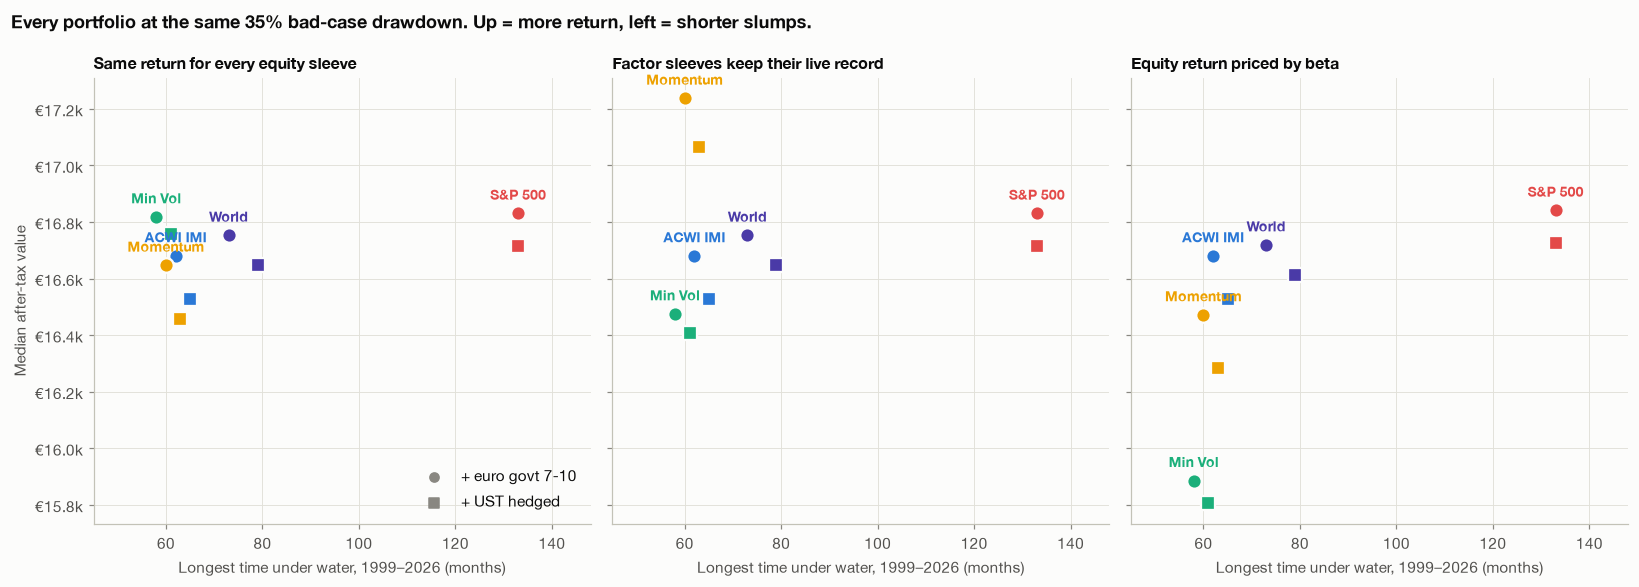

In [32]:
sub = OVT.xs("35%", level=0)
short = {"ACWI IMI": "ACWI IMI", "World": "World", "World Min Vol": "Min Vol", "World Momentum": "Momentum", "S&P 500": "S&P 500"}
fig, axes = plt.subplots(1, 3, figsize=(15, 5.4), sharey=True)
for ax, s in zip(axes, TGT):
    col = MED[s]
    for name, r_ in sub.iterrows():
        e, b = PORTS[name]
        ax.scatter(r_["Longest underwater (m)"], r_[col], s=90, color=pcol[e], marker="o" if b.startswith("EUR") else "s",
                   edgecolor=SURFACE, linewidth=1.5, zorder=3)
    for e in SHORT:   # one label per equity sleeve, placed at its euro-govt point
        r_ = sub.loc[f"{e} + Euro govt 7-10"]
        ax.annotate(short[e], (r_["Longest underwater (m)"], r_[col]), xytext=(0, 9), textcoords="offset points",
                    fontsize=9, color=pcol[e], fontweight="bold", ha="center")
    ax.yaxis.set_major_formatter(eur_k); ax.set_xlim(45, sub["Longest underwater (m)"].max() + 15)
    ax.set_xlabel("Longest time under water, 1999–2026 (months)"); ax.set_title(s, fontsize=10.5)
axes[0].set_ylabel("Median after-tax value")
axes[0].scatter([], [], marker="o", color=MUTED, label="+ euro govt 7-10")
axes[0].scatter([], [], marker="s", color=MUTED, label="+ UST hedged")
axes[0].legend(loc="lower right")
fig.suptitle("Every portfolio at the same 35% bad-case drawdown. Up = more return, left = shorter slumps.",
             x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

### 6c-bis · Return, volatility, alpha and beta — portfolio and each sleeve

Each portfolio at the weight that gives a 35% bad-case drawdown. Two views:

- **History, 1999–2026** (rebalanced monthly, after fund cost): what each sleeve and the mix actually did.
- **Simulation, next 10 years**, one block per return scenario: what the assumptions imply. *CAGR* is the
  expected compound return per year; *volatility* is annualised, from monthly returns.

**Alpha and beta** are measured against the market (MSCI ACWI IMI), in excess of cash. Beta is how much the
sleeve moves per 1% move of the market. Alpha is the return per year *not* explained by that beta; the
t-stat says whether history could tell it from zero (|t| above about 2). In the simulation, alpha is an
*input* — it is whatever the scenario assumes, which is why it is shown, not tested.

In [33]:
MKT_J = J["ACWI IMI"]
BOND2_LABEL = {v: k for k, v in BOND2.items()}
hist = {}
for name, (e, b) in PORTS.items():
    if not b.startswith("EUR"):
        continue
    we = float(RBT.loc[("35%", S_SAME, name), "Equity weight"])
    parts = {f"{e} (equity sleeve)": J[e], f"{BOND2_LABEL[b]} (bond sleeve)": J[b], f"Portfolio, {we:.0%} equity": we * J[e] + (1 - we) * J[b]}
    for k, r_ in parts.items():
        ab = D.alpha_beta(r_, MKT_J, rfJ)
        hist[(name, k)] = {"CAGR": pf.perf_stats(r_)["CAGR"], "Volatility": r_.std() * np.sqrt(12),
                           "Beta": ab["Beta"], "Alpha /yr": ab["Alpha /yr"], "Alpha t-stat": ab["Alpha t-stat"]}
HIST = pd.DataFrame(hist).T
print("History 1999–2026, after fund cost (World before 2001 is ACWI IMI):")
display(HIST.style.format({"CAGR": "{:.1%}", "Volatility": "{:.1%}", "Beta": "{:.2f}", "Alpha /yr": "{:+.2%}", "Alpha t-stat": "{:+.1f}"})
        .background_gradient(cmap="RdYlGn", subset=["Alpha t-stat"], vmin=-3, vmax=3))

History 1999–2026, after fund cost (World before 2001 is ACWI IMI):


In [34]:
ci = list(X.columns).index
rf_m = (1 + RF_CMA) ** (1 / 12) - 1
sim = {}
for s in TGT:
    P = PATHS[s]
    mkt = P[..., ci("ACWI IMI")]
    for name, (e, b) in PORTS.items():
        if not b.startswith("EUR"):
            continue
        we = float(RBT.loc[("35%", S_SAME, name), "Equity weight"])
        res = D.pac_paths_rule(P, wvec(e, we, {b: 1.0}), TAX, "split")
        o = D.outcome_summary(res, H)
        for k, r_ in {f"{e} (equity sleeve)": P[..., ci(e)], f"{BOND2_LABEL[b]} (bond sleeve)": P[..., ci(b)]}.items():
            ab = D.alpha_beta(r_, mkt, rf_m)
            sim[(SCN[s], name, k)] = {"CAGR": np.exp(np.log1p(r_).mean() * 12) - 1, "Volatility": r_.std() * np.sqrt(12),
                                      "Beta": ab["Beta"], "Alpha /yr": ab["Alpha /yr"]}
        ab = D.alpha_beta(res["twr"], mkt, rf_m)
        sim[(SCN[s], name, f"Portfolio, {we:.0%} equity")] = {"CAGR": o["CAGR"], "Volatility": o["Volatility"],
                                                               "Beta": ab["Beta"], "Alpha /yr": ab["Alpha /yr"]}
SIMS = pd.DataFrame(sim).T
SIMS.index.names = ["Scenario", "Portfolio", "Line"]
print("Simulated, next 10 years. Portfolio line = the account's own return (contributions drift the mix; no rebalancing).")
display(SIMS.style.format({"CAGR": "{:.2%}", "Volatility": "{:.1%}", "Beta": "{:.2f}", "Alpha /yr": "{:+.2%}"}))

Simulated, next 10 years. Portfolio line = the account's own return (contributions drift the mix; no rebalancing).


**The simulated outcome, split by sleeve.** Where the euros come from at the end of the plan, on the
median path of each sleeve (the medians of the parts do not add up exactly to the median of the whole), in
the live-record scenario. Paid in is fixed by the weight; the rest is simulated.

In [35]:
split = {}
for name, (e, b) in PORTS.items():
    if not b.startswith("EUR"):
        continue
    we = float(RBT.loc[("35%", S_SAME, name), "Equity weight"])
    res = D.pac_paths_rule(PATHS[S_LIVE], wvec(e, we, {b: 1.0}), TAX, "split")
    for k, j in {f"{e}": ci(e), f"{BOND2_LABEL[b]}": ci(b)}.items():
        v, bs, tx = res["sleeve_value"][:, j], res["sleeve_basis"][:, j], res["sleeve_tax"][:, j]
        split[(f"{name} ({we:.0%} equity)", k)] = {"Paid in €": bs[0], "Median value €": np.median(v),
                                                   "Median gain €": np.median(v - bs), "Median tax €": np.median(tx),
                                                   "Median after tax €": np.median(v - tx), "Bad case p5 after tax €": np.percentile(v - tx, 5),
                                                   "Share of final value": np.median(v / res["sleeve_value"].sum(axis=1))}
    tot = res["after_tax"]
    split[(f"{name} ({we:.0%} equity)", "Whole account")] = {"Paid in €": res["sleeve_basis"][0].sum(), "Median after tax €": np.median(tot),
                                                            "Bad case p5 after tax €": np.percentile(tot, 5),
                                                            "Median tax €": np.median(res["sleeve_tax"].sum(axis=1))}
SPL = pd.DataFrame(split).T
display(SPL.style.format({**EUR0([c for c in SPL.columns if c.endswith("€")]), "Share of final value": "{:.0%}"}, na_rep=""))

### 6f · What if bonds earn more than their yield?

The base case gives each bond fund today's yield less its fee. If the curve stays as steep as it is, a
constant-maturity fund also earns **roll-down** (§4a). Below, bonds get yield + roll-down — euro govt 7-10
then expects about 4.4% — in the live-record scenario. Equity weights are re-dialled to the 35% bad case.

In [36]:
T_RD = {k: v + (ROLL[k] if k in ROLL else 0) for k, v in TGT[S_LIVE].items()}
P_RD = D.bootstrap_on_targets(X, H, N, 12, seed=41, targets=T_RD)
rd_rows = {}
for name, (e, b) in PORTS.items():
    if not b.startswith("EUR"):
        continue
    for lab, P_ in {"Yield only (base case)": PATHS[S_LIVE], "Yield + roll-down": P_RD}.items():
        dd, wg = rising([-D.outcome_summary(D.pac_paths_rule(P_, wvec(e, w, {b: 1.0}), TAX, "split"), H)["p5 max DD"] for w in WG], WG)
        w = float(np.interp(0.35, dd, wg))
        o = D.outcome_summary(D.pac_paths_rule(P_, wvec(e, w, {b: 1.0}), TAX, "split"), H)
        rd_rows[(name, lab)] = {"Bond return assumed": T_RD[b] if "roll" in lab else TGT[S_LIVE][b], "Equity weight": w,
                                "Median €": o["Median €"], "Bad case p5 €": o["Bad case p5 €"], "CAGR": o["CAGR"]}
RDT = pd.DataFrame(rd_rows).T
display(RDT.style.format({"Bond return assumed": "{:.2%}", "Equity weight": "{:.0%}", **EUR0(["Median €", "Bad case p5 €"]), "CAGR": "{:.2%}"}))

### 6d · Reading the overview

**What the evidence settles:**
- **Bonds: euro-area government, 7-10 years.** It beats every other bond sleeve at equal risk, for every equity
  sleeve, under all three return assumptions. An all-maturity fund (Vanguard VGEA, Amundi PRAR) is an
  equivalent substitute, €15–60 behind, with lower fees and a verified 12.5% tax treatment. Euro govt 3-7
  costs about €85–170 at a 30% bad-case drawdown and
  is the choice if a 2022-style bond loss (−18% for 7-10, −12% for 3-7) would be hard to hold through.
  Hedged Treasuries cushion crashes better but, at today's hedging cost, pay less than they protect. If the
  curve stays steep and bonds also earn their roll-down (§6f), every option gains €100–240 and the ranking
  does not move.
- **Weight: a risk budget, not an estimate.** Choose the bad-case drawdown you could sit through without
  selling; §5e gives the equity weight that delivers it for each sleeve.
- **The risk measure does not decide anything (§5e-bis).** Matching on volatility, tail euros, the chance of
  a loss, real drawdowns or a risk-averse certainty equivalent gives the same leader as matching on drawdown.
- **Among the market-like sleeves, the choice is worth very little.** At the same risk, World, S&P 500 and
  ACWI IMI end within €150–160 of each other (under 1% of the outcome), and the gaps are mostly fund cost:
  the best World and S&P 500 funds beat their net indexes slightly (−0.04%, −0.19%/yr), the ACWI IMI fund
  trails its index by 0.09%.
- **Cost layers are small except tax.** At these weights, fund cost, the €1 fee, dealing spreads and stamp
  duty together cost €160–460 over the plan; tax costs €1,050–1,250.

**What the evidence does not settle — the choice that is genuinely yours.** It comes down to one question:
*will the two factor sleeves earn more or less than the market from here?*

| Portfolio (at a 35% bad-case drawdown) | Equity | Median: same return | Median: factors keep live record | Median: priced by beta | Longest time under water 1999–2026 | GFC fall | 2022 fall |
|---|---|---|---|---|---|---|---|
| **World Min Vol + euro govt 7-10** | 79% | €16,818 | €16,475 | €15,885 | 58 months | −28% | −8% |
| **World Momentum + euro govt 7-10** | 57% | €16,647 | €17,237 | €16,471 | 60 months | −26% | −17% |
| **World + euro govt 7-10** | 61% | €16,753 | €16,753 | €16,718 | 73 months | −30% | −15% |
| **S&P 500 + euro govt 7-10** | 61% | €16,830 | €16,830 | €16,841 | 133 months | −27% | −14% |
| **ACWI IMI + euro govt 7-10** | 61% | €16,680 | €16,680 | €16,680 | 62 months | −31% | −16% |

- **Min vol is the most stable option by a clear margin**: the shallowest real falls, the smallest loss in
  2022, the shortest time under water. What it costs depends on what low-risk stocks earn: nothing if they
  keep earning the market return, about €340 (2%) if they repeat their live record since 2008 (0.86× the
  market's excess return), about €930 (5.5%) if they earn only what their beta implies.
- **Momentum is the highest-return option only if its premium persists.** Since its 2013 launch it earned
  1.31× the market's excess return (+3.4%/yr), and if that continues it ends about €480 ahead of World at the
  same risk. If its premium is gone, it is about €100 *behind* (a higher fund cost and deeper falls force a
  lower equity weight), and priced by beta about €250 behind. Its live alpha has a t-stat of about 1.8 — suggestive,
  not established — and §2c showed that return rankings in this universe tend to *reverse* from one decade
  to the next. It is also the least stable on 2022 (−17%) and needs only 57% equity to reach the 35% budget
  because its falls are deeper than the market's.
- **World is the cheapest way to own the market** on Trade Republic and is never more than €125 from the best
  market-like option.
- **S&P 500 is not better at equal risk by more than its fund-cost advantage** — the simulation gives US and
  world equity the same expected return, as the 2026 capital-market assumptions do (several rank the US
  *below* the rest of the world) — and its time under water after 2000 was the longest of all: 11 years.
- **ACWI IMI** adds emerging markets and small caps for 0.13%/yr more in measured fund cost than World, which
  is why it trails it here; the diversification is real, the price is about €40–75 over the plan.

Not financial advice. The simulation re-centres history on published assumptions; it is a way to compare
options under the same conditions, not a forecast.

### 6e · The funds, concretely

For each sleeve: the fund the analysis used, and the alternative worth knowing about. All accumulating,
physically replicated, Irish or Luxembourg UCITS. **Check every ISIN in the Trade Republic app before the
first order** — Trade Republic does not publish its savings-plan list, so availability comes from broker
comparison sites.

| Sleeve | Fund | ISIN | TER | Measured cost /yr | Alternative |
|---|---|---|---|---|---|
| World | Xtrackers MSCI World 1C (XDWD) | IE00BJ0KDQ92 | 0.12% | −0.04% | iShares Core MSCI World IE00B4L5Y983 (0.20%, largest, −0.03%) |
| ACWI IMI | SPDR MSCI ACWI IMI (SPYI) | IE00B3YLTY66 | 0.17% | +0.09% | SPDR MSCI ACWI IE00B44Z5B48 (0.12%, no small caps, +0.04%) |
| World Min Vol | iShares Edge MSCI World Min Vol (IQQ0) | IE00B8FHGS14 | 0.30% | +0.04% | Xtrackers IE00BL25JN58 (0.25%, +0.05%) |
| World Momentum | Xtrackers MSCI World Momentum 1C (XDEM) | IE00BL25JP72 | 0.25% | +0.08% | iShares Edge MSCI World Momentum IE00BP3QZ825 (0.25%, larger, +0.23%) |
| S&P 500 | iShares Core S&P 500 (SXR8) | IE00B5BMR087 | 0.07% | −0.19% | Vanguard IE00BFMXXD54 (0.07%), SPDR IE000XZSV718 (0.03%) — too young to measure |
| Euro govt 7-10 | Xtrackers II Eurozone Govt Bond 7-10 1C (X710) | LU0290357259 | 0.15% | — | iShares € Govt Bond 7-10yr IE00B3VTN290 (0.15%) — tracks identically |
| Euro govt all maturities (substitute for 7-10) | Vanguard EUR Eurozone Govt Bond Acc (VGEA) | IE00BH04GL39 | 0.07% | — | Amundi Prime Euro Govies LU2089238898 (0.05%, 99.9% white list) |
| Euro govt 3-7 | iShares € Govt Bond 3-7yr (SXRP) | IE00B3VTML14 | 0.15% | — | Xtrackers Eurozone Govt 3-5 LU0290356954 (shorter, 3-5 yr) |
| UST hedged | Vanguard USD Treasury Bond EUR Hedged (VDTE) | IE00BMX0B631 | 0.08% | — | Amundi US Treasury 7-10Y EUR Hedged LU1407888137 (0.10%, 99.7% white list) |

Measured cost for bond funds is not shown: it cannot be separated from the modelling error of the
rebuilt index (§4). For the equity funds it is the trend of the gap to the official MSCI or S&P index.

## 7 · The portfolio at a chosen risk level

**The risk level.** Defined with the investor through four questions — capacity (no planned need for the
money, but a thin emergency fund: equity capped near 50%), a coin flip (+50% / −16% is the largest loss
accepted, a moderate risk aversion whose best weight here is about 50% equity), the largest one-year fall
they would sit through (about €2,800 late in the plan) and past behaviour (held through 2020 and 2022).
All four point to the same place: **a bad-case drawdown of 30%** — the account falls to 30% below its
high, relative to what was paid in, in one path in twenty.

**The search.** Every equity sleeve and 50/50 blends of them, with each euro bond sleeve, each dialled to
that 30% under each return scenario. Because no scenario can be chosen on evidence, the portfolios are
ranked on their **worst-scenario median** — the outcome you can count on whichever scenario turns out
true — and the spread between scenarios shows how much each one is a bet.

In [37]:
EQB = {"World": {"World": 1}, "S&P 500": {"S&P 500": 1}, "ACWI IMI": {"ACWI IMI": 1},
       "World Min Vol": {"World Min Vol": 1}, "World Momentum": {"World Momentum": 1},
       "50/50 World + Min Vol": {"World": .5, "World Min Vol": .5},
       "50/50 World + Momentum": {"World": .5, "World Momentum": .5},
       "50/50 Min Vol + Momentum": {"World Min Vol": .5, "World Momentum": .5}}
BDB = {"Euro govt 7-10": {"EUR Govt 7-10": 1}, "Euro govt all": {"EUR Govt All": 1}, "Euro govt 3-7": {"EUR Govt 3-7": 1}}
RISK_T = 0.30
WF = np.round(np.arange(0.3, 1.001, 0.05), 2)

def wmix(em, bm, we):
    d = {**{k: we * v for k, v in em.items()}, **{k: (1 - we) * v for k, v in bm.items()}}
    return np.array([d.get(c, 0.0) for c in X.columns])

def weight_for(P, em, bm, t=RISK_T):
    dd, wg = rising([-D.outcome_summary(D.pac_paths_rule(P, wmix(em, bm, w), TAX, "split"), H)["p5 max DD"] for w in WF], WF)
    return float(np.interp(t, dd, wg))

tl = {}
for en, em in EQB.items():
    for bn, bm in BDB.items():
        r = {}
        for s, P in PATHS.items():
            we = weight_for(P, em, bm)
            o = D.outcome_summary(D.pac_paths_rule(P, wmix(em, bm, we), TAX, "split"), H)
            r[f"Median € ({SCN[s]})"] = o["Median €"]
            if s == S_SAME:
                r = {"Equity weight": we, **r, "Bad case p5 €": o["Bad case p5 €"], "P(end < paid in)": o["P(end < paid in)"]}
        p = sum(r["Equity weight"] * v * J[k] for k, v in em.items()) + sum((1 - r["Equity weight"]) * v * J[k] for k, v in bm.items())
        ct = D.crisis_table(p.to_frame("x"))["x"]
        r |= {"GFC fall": ct["GFC 2007-09"], "2022 fall": ct["Inflation 2022"],
              "Longest underwater (m)": pf.perf_stats(p)["Longest underwater (m)"]}
        tl[(en, bn)] = r
TL7 = pd.DataFrame(tl).T
meds = [c for c in TL7 if c.startswith("Median")]
TL7["Worst-scenario median €"] = TL7[meds].min(axis=1)
TL7["Spread between scenarios €"] = TL7[meds].max(axis=1) - TL7["Worst-scenario median €"]
TL7 = TL7.sort_values("Worst-scenario median €", ascending=False)
display(TL7.style.format({"Equity weight": "{:.0%}", **EUR0(meds + ["Bad case p5 €", "Worst-scenario median €", "Spread between scenarios €"]),
                          "P(end < paid in)": "{:.1%}", "GFC fall": "{:.1%}", "2022 fall": "{:.1%}", "Longest underwater (m)": "{:.0f}"})
        .background_gradient(cmap="Greens", subset=["Worst-scenario median €"])
        .background_gradient(cmap="Reds", subset=["Spread between scenarios €"]))
print(f"Every row is dialled to a {RISK_T:.0%} bad-case drawdown (equity weight shown for the same-return scenario).")

Every row is dialled to a 30% bad-case drawdown (equity weight shown for the same-return scenario).


### 7a · The recommended portfolio

**World (Xtrackers XDWD) + euro government 7-10 (Xtrackers X710), 50/50.** (The exact weight for a 30% bad case is 52%; rounded to 50% it is €50 + €50 a month, with a bad case of 29%.) It is the most
robust choice at this risk level: within €45–80 of the best median in every scenario, with no exposure to
the one assumption the evidence cannot settle (what factor sleeves will earn). S&P 500 edges it by about
€45–80 on fund cost alone, but its time under water after 2000 was 74 months against 60, and it is one
country. The factor sleeves and blends either lead in one scenario and trail in another (momentum: up to
€630 between scenarios) or, for min vol, buy a smaller 2022 loss with a lower worst case.

Below: the plan concretely, its outcome distribution, and the outcome at one step less and one step
more risk.

In [38]:
REC = ({"World": 1}, {"EUR Govt 7-10": 1})
we_rec = round(weight_for(PATHS[S_SAME], *REC) * 20) / 20       # rounded to 5 points for a plan you can set up
plan = pd.DataFrame({"Fund": ["Xtrackers MSCI World 1C (XDWD)", "Xtrackers II Eurozone Govt Bond 7-10 1C (X710)"],
                     "ISIN": ["IE00BJ0KDQ92", "LU0290357259"], "Share": [we_rec, 1 - we_rec],
                     "Initial €1,000": [1000 * we_rec, 1000 * (1 - we_rec)], "Monthly €100": [100 * we_rec, 100 * (1 - we_rec)]},
                    index=["Equity", "Bonds"])
display(plan.style.format({"Share": "{:.0%}", "Initial €1,000": "€{:,.0f}", "Monthly €100": "€{:,.0f}"}))
print("Substitutes: euro govt all maturities (Vanguard VGEA IE00BH04GL39, 0.07%) for X710 — €15–60 less at equal risk;")
print("iShares Core MSCI World (IE00B4L5Y983, 0.20%) for XDWD — same index, measured cost within 0.01%.")

out = {}
for lab, we in {f"One step safer ({we_rec - .1:.0%})": we_rec - .1, f"Recommended ({we_rec:.0%})": we_rec,
                f"One step riskier ({we_rec + .1:.0%})": we_rec + .1}.items():
    res = D.pac_paths_rule(PATHS[S_SAME], wmix(*REC, we), TAX, "split")
    o = D.outcome_summary(res, H)
    v = res["values"]
    out[lab] = {"Median €": o["Median €"], "Good case p95 €": o["Good case p95 €"], "Bad case p5 €": o["Bad case p5 €"],
                "Median IRR": o["Median IRR"], "P(end < paid in)": o["P(end < paid in)"], "P(real loss)": o["P(real loss)"],
                "Bad-case drawdown": -o["p5 max DD"], "1-in-20 worst 12-month fall €": np.percentile((v[:, 12:] - v[:, :-12] - 1200).min(axis=1), 5)}
OUT = pd.DataFrame(out)
display(OUT.style.format("€{:,.0f}", subset=pd.IndexSlice[["Median €", "Good case p95 €", "Bad case p5 €", "1-in-20 worst 12-month fall €"], :])
        .format("{:.1%}", subset=pd.IndexSlice[["Median IRR", "P(end < paid in)", "P(real loss)", "Bad-case drawdown"], :]))
print("€13,000 paid in; after 26%/12.5% tax, stamp duty, fees and fund costs. Same-return scenario.")

,Fund,ISIN,Share,"Initial €1,000",Monthly €100
Equity,Xtrackers MSCI World 1C (XDWD),IE00BJ0KDQ92,50%,€500,€50
Bonds,Xtrackers II Eurozone Govt Bond 7-10 1C (X710),LU0290357259,50%,€500,€50


Substitutes: euro govt all maturities (Vanguard VGEA IE00BH04GL39, 0.07%) for X710 — €15–60 less at equal risk;
iShares Core MSCI World (IE00B4L5Y983, 0.20%) for XDWD — same index, measured cost within 0.01%.


,One step safer (40%),Recommended (50%),One step riskier (60%)
Median €,"€16,373","€16,527","€16,725"
Good case p95 €,"€19,981","€20,929","€22,009"
Bad case p5 €,"€13,447","€13,070","€12,550"
Median IRR,4.2%,4.4%,4.6%
P(end < paid in),2.7%,4.7%,7.4%
P(real loss),15.2%,17.0%,18.8%
Bad-case drawdown,23.7%,28.8%,34.4%
1-in-20 worst 12-month fall €,"€-2,325","€-2,831","€-3,475"


€13,000 paid in; after 26%/12.5% tax, stamp duty, fees and fund costs. Same-return scenario.


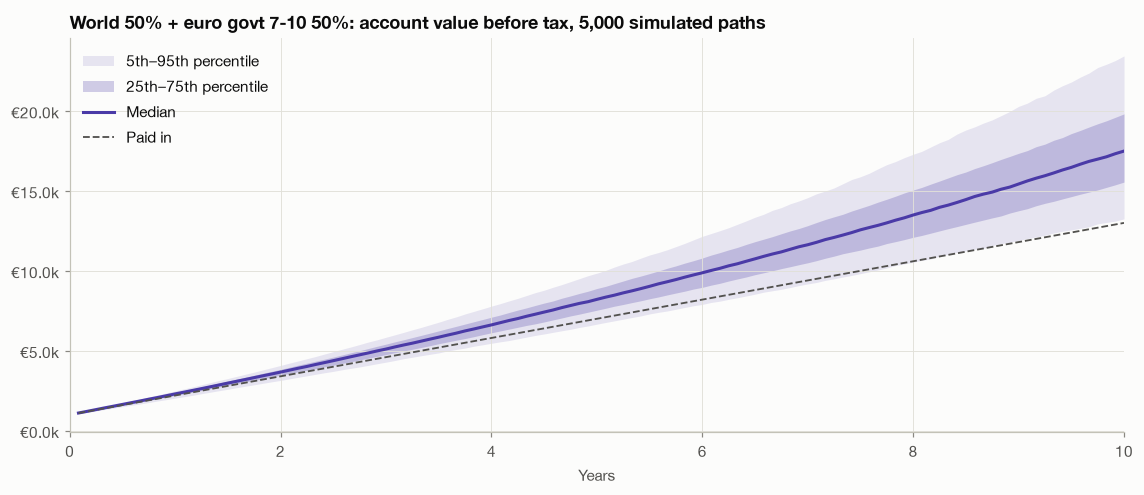

Equity share at year 10 without rebalancing: median 55%, 5th–95th percentile 37%–68%.


In [39]:
res = D.pac_paths_rule(PATHS[S_SAME], wmix(*REC, we_rec), TAX, "split")
q = np.percentile(res["values"], [5, 25, 50, 75, 95], axis=0)
mo = np.arange(1, H + 1) / 12
paid_ = 1000 + 100 * np.arange(1, H + 1)
fig, ax = plt.subplots(figsize=(10.5, 4.6))
ax.fill_between(mo, q[0], q[4], color=SLOT[4], alpha=0.12, lw=0, label="5th–95th percentile")
ax.fill_between(mo, q[1], q[3], color=SLOT[4], alpha=0.25, lw=0, label="25th–75th percentile")
ax.plot(mo, q[2], color=SLOT[4], lw=2, label="Median")
ax.plot(mo, paid_, color=INK2, lw=1.2, ls="--", label="Paid in")
ax.yaxis.set_major_formatter(eur_k); ax.set_xlabel("Years"); ax.set_xlim(0, 10)
ax.set_title(f"World {we_rec:.0%} + euro govt 7-10 {1 - we_rec:.0%}: account value before tax, 5,000 simulated paths")
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()
eqsh = res["sleeve_value"][:, list(X.columns).index("World")] / res["sleeve_value"].sum(axis=1)
print(f"Equity share at year 10 without rebalancing: median {np.median(eqsh):.0%}, "
      f"5th–95th percentile {np.percentile(eqsh, 5):.0%}–{np.percentile(eqsh, 95):.0%}.")

### 7b · Running it

- **Set up two savings plans** in the shares above, on the same day of the month. Buy the €1,000 as two
  one-off orders (€1 each).
- **No rebalancing by selling.** Selling triggers tax. The simulation assumes none; the mix drifts towards
  equity as it grows (to 55% by year 10 on the median path, 68% on the 95th percentile), which is already in the numbers above.
  If equity drifts above about 60% after a long rally, redirect the monthly €100 to bonds for a few months
  rather than selling.
- **Review once a year, not after a fall.** Re-check the risk answers if the emergency fund, income or
  horizon changes. A fall is when the plan is doing its job, not when to change it.
- **The thin emergency fund** is the one weak point: until it covers 3–6 months of expenses, do not raise
  the equity share, whatever the market does.
- **Check on the first sale** that Trade Republic taxes the bond fund's gain at 12.5%.